<a href="https://colab.research.google.com/github/Vukhanhvan09/Automated-Customer-Feedback-Sentiment-Analysis-System./blob/main/Automated_Customer_Feedback_Sentiment_Analysis_Systemipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving tiki_dataset.zip to tiki_dataset.zip


In [ ]:
import zipfile

with zipfile.ZipFile('tiki_dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('tiki_dataset')

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import classification_report, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score
from sklearn.model_selection import RandomizedSearchCV

#**PHẦN A — TIỀN XỬ LÝ & PHÂN TÍCH VĂN BẢN**

## **A.1 Khám phá dữ liệu ban đầu**

### **Câu A1:**

In [ ]:
data = []
folder_path = "tiki_dataset/tiki_dataset"
for file in os.listdir(folder_path):
    if file.endswith(".txt"):
        file_path = os.path.join(folder_path, file)
        with open(file_path, "r", encoding="utf-8") as f:
            lines = f.readlines()
            for line in lines:
                parts = line.strip().split("\t")
                if len(parts) == 8:
                    data.append(parts)
print("Số dòng dữ liệu:", len(data))

Số dòng dữ liệu: 13652


In [ ]:
columns = [
    "product_id",
    "customer_name",
    "rating",
    "review_title",
    "helpful_votes",
    "verified_purchase",
    "review_date",
    "review_text"
]
df = pd.DataFrame(data, columns=columns)
df.to_csv("tiki_reviews.csv", index=False, encoding= "utf-8-sig")

In [ ]:
#Câu A1
df = pd.read_csv("tiki_reviews.csv")
df.head(10)

,product_id,customer_name,rating,review_title,helpful_votes,verified_purchase,review_date,review_text
0,BiaCongPlusF47Cm,Phạm Hương,100,giữ được tài liệu chắc chắn,0,False,4 tháng trước,"Bìa cứng , chất_liệu dầy giúp giữ giấy_tờ phẳ..."
1,BiaCongPlusF47Cm,Trần Nhung,100,Tốt,0,False,4 tháng trước,Bìa có kích_thước khá lớn có_thể đựng được rấ...
2,BiaCongPlusF47Cm,Indre,100,Bìa Còng Plus F4 7cm,0,False,5 tháng trước,Mình rất thích sản_phẩm Bìa_Còng_Plus_F4_7cm ...
3,BiaCongPlusF47Cm,Tooya Hondo,100,Tốt,0,False,5 tháng trước,Sản phẩm bìa còng plus F4 7cm của hãng ...
4,BiaCongPlusA45Cm,Indre,100,Bìa Còng Plus A4 5cm,0,False,5 tháng trước,Sản_phẩm Bìa_Còng_Plus_A4_5cm khiến mình rất ...
5,BiaCongPlusF45Cm,Trang,100,Tốt,0,False,4 tháng trước,"Bìa_Còng_Plus_F4_5cm , giá_cả phù_hợp , phải_..."
6,BiaCongPlusA47Cm,Ocsan Hatsunemiku,100,hữu dụng,0,False,2 tháng trước,"đây là sản phẩm có công dụng rất tốt ,..."
7,BiaLaPlus60P,Phạm Ánh Loan,80,Giữ vững chất lượng,0,True,3 tháng trước,Bìa_Lá_Plus_60P đã tiếp_tục là sản_phẩm tốt c...
8,BiaLaPlus60P,Phạm Hương,80,đựng nhiều hồ sơ,0,False,3 tháng trước,"Bộ có nhiều màu_sắc , có_thể đựng nhiều hồ_sơ..."
9,BiaLaPlus60P,Nguyễn Trinh,100,bìa lá,0,True,4 tháng trước,"Mình chấm nhất hàng của Plus là sắc_màu , ngọ..."


In [ ]:
# from google.colab import files
# files.download('tiki_reviews.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13652 entries, 0 to 13651
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   product_id         13652 non-null  object
 1   customer_name      13652 non-null  object
 2   rating             13652 non-null  int64 
 3   review_title       13652 non-null  object
 4   helpful_votes      13652 non-null  int64 
 5   verified_purchase  13652 non-null  bool  
 6   review_date        13652 non-null  object
 7   review_text        13652 non-null  object
dtypes: bool(1), int64(2), object(5)
memory usage: 760.1+ KB


In [ ]:
df.shape

(13652, 8)

In [ ]:
df["rating"] = df["rating"].astype("int", errors="ignore")
def gan_nhan(rating):
  if rating >= 80:
    return "positive"
  elif rating >= 50 and rating < 80:
    return "neutral"
  else:
    return "negative"
df["sentiment"] = df["rating"].apply(gan_nhan)
df.head(10)

,product_id,customer_name,rating,review_title,helpful_votes,verified_purchase,review_date,review_text,sentiment
0,BiaCongPlusF47Cm,Phạm Hương,100,giữ được tài liệu chắc chắn,0,False,4 tháng trước,"Bìa cứng , chất_liệu dầy giúp giữ giấy_tờ phẳ...",positive
1,BiaCongPlusF47Cm,Trần Nhung,100,Tốt,0,False,4 tháng trước,Bìa có kích_thước khá lớn có_thể đựng được rấ...,positive
2,BiaCongPlusF47Cm,Indre,100,Bìa Còng Plus F4 7cm,0,False,5 tháng trước,Mình rất thích sản_phẩm Bìa_Còng_Plus_F4_7cm ...,positive
3,BiaCongPlusF47Cm,Tooya Hondo,100,Tốt,0,False,5 tháng trước,Sản phẩm bìa còng plus F4 7cm của hãng ...,positive
4,BiaCongPlusA45Cm,Indre,100,Bìa Còng Plus A4 5cm,0,False,5 tháng trước,Sản_phẩm Bìa_Còng_Plus_A4_5cm khiến mình rất ...,positive
5,BiaCongPlusF45Cm,Trang,100,Tốt,0,False,4 tháng trước,"Bìa_Còng_Plus_F4_5cm , giá_cả phù_hợp , phải_...",positive
6,BiaCongPlusA47Cm,Ocsan Hatsunemiku,100,hữu dụng,0,False,2 tháng trước,"đây là sản phẩm có công dụng rất tốt ,...",positive
7,BiaLaPlus60P,Phạm Ánh Loan,80,Giữ vững chất lượng,0,True,3 tháng trước,Bìa_Lá_Plus_60P đã tiếp_tục là sản_phẩm tốt c...,positive
8,BiaLaPlus60P,Phạm Hương,80,đựng nhiều hồ sơ,0,False,3 tháng trước,"Bộ có nhiều màu_sắc , có_thể đựng nhiều hồ_sơ...",positive
9,BiaLaPlus60P,Nguyễn Trinh,100,bìa lá,0,True,4 tháng trước,"Mình chấm nhất hàng của Plus là sắc_màu , ngọ...",positive


In [ ]:
df["sentiment"].value_counts()

,count
sentiment,
positive,11684
neutral,1614
negative,354


Câu A1:
- Bộ dữ liệu ban đầu bao gồm các file .txt thô, không được phân theo hàng, cột. Các dữ liệu cách nhau bởi dấu cách đơn thuần, gây khó khăn cho việc phân tích và trực quan hoá dữ liệu.
- Dựa vào các bước xử lý ban đầu, nhóm tiến hành gộp toàn bộ dữ liệu trong các file .txt thành 1 dataFrame lớn, đặt tên cho các cột dữ liệu và chuyển đổi sang file .csv
- Bộ dữ liệu sau khi chuyển đổi bao gồm 13652 mẫu và 8 cột dữ liệu lần lượt là:
  + product_id: mã/tên sản phẩm
  + customer_name: tên khách hàng
  + rating: điểm đánh giá sản phẩm
  + review_title: tiêu đề đánh giá sản phẩm
  + helpful_votes: bình chọn đánh giá hữu ích
  + verified_purchase: xác thực mua hàng
  + review_date: thời gian đánh giá
  + review_text: nội dung đánh giá
- Ban đầu, đa phần các cột trong bộ dữ liệu đều mang kiểu dữ liệu "object" ngoại trừ cột helpful_votes có kiểu dữ liệu là "int" và cột verified_purchase có kiểu dữ liệu "boolean"
- Để phục vụ bài toán phân tích cảm xúc, nhóm đã chia bộ dữ liệu theo 3 nhãn dựa vào số điểm mà khách hàng đánh giá cho sản phẩm. Cụ thể:
  + Nếu rating >= 80, mẫu dữ liệu sẽ được gán nhãn "positive"(tổng cộng có 11684 mẫu)
  + Nếu rating nằm trong khoảng từ 50 đến nhỏ hơn 80, mẫu dữ liệu sẽ được gán nhãn "neutral" (tổng cộng có 1614 mẫu)
  + Cuối cùng, nếu rating < 50, mẫu dữ liệu sẽ được gán nhãn "negative" (tổng cộng 354 mẫu)
- Nhận xét:ta có thể dễ dàng nhận thấy dữ liệu đang bị mất cân bằng nghiêm trọng khi số lượng mẫu "positive" áp đảo số lượng mẫu "neutral" và "negative". Điều này gây ảnh hưởng lớn đến quá trình huấn luyện mô hình:
  + Mô hình dễ thiên về dự đoán lớp positive.
  + Độ chính xác của mô hình có thể cao nhưng khả năng nhận diện negative và neutral rất kém.
  + Recall và F1-score của lớp negative và lớp neutral có thể thấp.





### **Câu A2**

In [ ]:
df["ky_tu"] = df["review_text"].str.len()
df["so_tu"] = df["review_text"].str.split().str.len()
df.groupby("sentiment")[["ky_tu"]].describe()


ky_tu                                                       \
             count        mean         std    min     25%    50%    75%   
sentiment                                                                 
negative     354.0  352.429379  134.554840  201.0  253.25  305.5  409.0   
neutral     1614.0  324.330855  102.576176  165.0  251.00  292.0  367.5   
positive   11684.0  328.408507  107.063820  120.0  257.00  297.0  367.0   

                   
              max  
sentiment          
negative   1110.0  
neutral    1004.0  
positive   2082.0

In [ ]:
df.groupby("sentiment")[["so_tu"]].describe()

so_tu                                                     
             count       mean        std   min   25%   50%   75%    max
sentiment                                                              
negative     354.0  76.706215  29.158522  40.0  55.0  67.5  88.0  217.0
neutral     1614.0  69.824659  22.476955  38.0  54.0  63.0  80.0  226.0
positive   11684.0  69.537658  23.029179  28.0  54.0  63.0  78.0  424.0

In [ ]:
df.groupby("sentiment")[["ky_tu", "so_tu"]].mean()

,ky_tu,so_tu
sentiment,,
negative,352.429379,76.706215
neutral,324.330855,69.824659
positive,328.408507,69.537658


Câu A2:
- Nhóm tiến hành tính toán độ dài văn bản dựa trên hai tiêu chí là số ký tự và số từ trong mỗi đánh giá. Kết quả cho thấy các đánh giá thuộc nhãn Negative có độ dài trung bình lớn nhất với khoảng 352 ký tự và 76 từ. Trong khi đó, các đánh giá Positive và Neutral có độ dài khá tương đồng, dao động trong khoảng 324-328 ký tự và 69-70 từ. Điều này cho thấy khách hàng không hài lòng về sản phẩm thường có xu hướng viết đánh giá chi tiết hơn nhằm mô tả các vấn đề bản thân họ đã gặp phải trong quá trình sử dụng sản phẩm. Ngược lại, các đánh giá tích cực và trung lập thường ngắn gọn và tập trung nhiều vào cảm nhận chung về sản phẩm hơn.
- Dựa vào số liệu vừa được tính toán, ta có thể thấy tuy có sự chênh lệch về độ dài văn bản giữa các nhãn nhưng phần chênh lệch này lại không quá lớn. Văn bản có nhãn Negative chỉ nhiều hơn khoảng 7 từ so với văn bản ở nhãn Neutral và Positive. Bên cạnh đó, độ lệch chuẩn của các nhãn đều ở mức khá cao với Negative khoảng 29 từ, Neutral khoảng 22 từ và Positive khoảng 23 từ. Điều này cho thấy ở mỗi nhãn đều tồn tại nhiều bài đánh giá có độ dài hay ngắn khác nhau. Do đó,có thể nhận xét rằng độ dài của văn bản không cho thấy mối tương quan rõ ràng với các nhãn phân loại.
- Nói tóm lại, độ dài văn bản có thể cung cấp một số thông tin hỗ trợ cho việc phân loại nhãn cảm xúc nhưng không phải yếu tố quyết định. Mặc dù các đánh giá tiêu cực có xu hướng dài hơn các đánh giá tích cực hay trung lập nhưng sự khác biệt này không đủ lớn để sử dụng cho việc phân loại. Cần phải khai thác thêm nội dung và từ vựng của văn bản đó.

## **A.2 Tiền xử lý văn bản**

### **Câu A3**

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving vietnamese-stopwords-dash.txt to vietnamese-stopwords-dash.txt


In [ ]:
with open("vietnamese-stopwords-dash.txt", "r", encoding="utf-8") as f:
    stopwords = f.read().splitlines()
print(stopwords[:10])

['a_lô', 'a_ha', 'ai', 'ai_ai', 'ai_nấy', 'ai_đó', 'alô', 'amen', 'anh', 'anh_ấy']


Do Python không hỗ trợ các stopword của tiếng Việt, nhóm đã sử dụng một file stopwords tiếng việt bên ngoài (vietnamese-stopwords-dash.txt) được tải lên Google Colab. Chương trình sẽ mở file ở chế độ đọc, mã hoá toàn bộ nội dung của file thành một chuỗi sau đó tách chuỗi này thành một danh sách mà trong đó mỗi dòng của tập tin tương ứng với một phần tử. Danh sách này sẽ được sử dụng ở các bước tiền xử lý tiếp theo nhằm loại bỏ các từ xuất hiện với tần suất lớn trong bộ dữ liệu cần phân tích nhưng không có nhiều tác dụng trong việc phân loại và xây dựng các mô hình sau này.
- Link github của file stopwords: https://github.com/stopwords/vietnamese-stopwords.git


In [ ]:
keep_words = [
    "không",
    "chẳng",
    "tốt"

]
for word in keep_words:
  if word in stopwords:
    stopwords.remove(word)
print(stopwords[:1000])

['a_lô', 'a_ha', 'ai', 'ai_ai', 'ai_nấy', 'ai_đó', 'alô', 'amen', 'anh', 'anh_ấy', 'ba', 'ba_ba', 'ba_bản', 'ba_cùng', 'ba_họ', 'ba_ngày', 'ba_ngôi', 'ba_tăng', 'bao_giờ', 'bao_lâu', 'bao_nhiêu', 'bao_nả', 'bay_biến', 'biết', 'biết_bao', 'biết_bao_nhiêu', 'biết_chắc', 'biết_chừng_nào', 'biết_mình', 'biết_mấy', 'biết_thế', 'biết_trước', 'biết_việc', 'biết_đâu', 'biết_đâu_chừng', 'biết_đâu_đấy', 'biết_được', 'buổi', 'buổi_làm', 'buổi_mới', 'buổi_ngày', 'buổi_sớm', 'bà', 'bà_ấy', 'bài', 'bài_bác', 'bài_bỏ', 'bài_cái', 'bác', 'bán', 'bán_cấp', 'bán_dạ', 'bán_thế', 'bây_bẩy', 'bây_chừ', 'bây_giờ', 'bây_nhiêu', 'bèn', 'béng', 'bên', 'bên_bị', 'bên_có', 'bên_cạnh', 'bông', 'bước', 'bước_khỏi', 'bước_tới', 'bước_đi', 'bạn', 'bản', 'bản_bộ', 'bản_riêng', 'bản_thân', 'bản_ý', 'bất_chợt', 'bất_cứ', 'bất_giác', 'bất_kì', 'bất_kể', 'bất_kỳ', 'bất_luận', 'bất_ngờ', 'bất_nhược', 'bất_quá', 'bất_quá_chỉ', 'bất_thình_lình', 'bất_tử', 'bất_đồ', 'bấy', 'bấy_chầy', 'bấy_chừ', 'bấy_giờ', 'bấy_lâu', 'bấy_lâ

Mặc dù sử dụng bộ stopwords tiếng Việt có sẵn, nhóm nhận thấy một số từ phủ định như "không", "chẳng" hay các từ mang ý nghĩa phân loại cao như từ "tốt" có vai trò rất quan trọng trong việc biểu đạt cảm xúc của người dùng. Các từ này có khả năng làm thay đổi hay làm mất hoàn toàn ý nghĩa của câu đánh giá nên cần được loại bỏ khỏi danh sách stopwords để giữ lại trong quá trình tiền xử lý và huấn luyện mô hình.

In [ ]:
domain_stopwords = {
    "sản_phẩm",
    "shop",
    "mua",
    "dùng",
    "hàng",
    "giao_hàng",
    "giá",
    "giá_cả",
    "màu",
    "bé",
    "thử",
    "tiki",
    "lắm",
    "sử_dụng"
}
stopwords = set(stopwords)
stopwords.update(domain_stopwords)

In [ ]:
# with open("stopwords.txt", "w", encoding="utf-8") as f:
#     for word in sorted(stopwords):
#         f.write(word + "\n")

In [ ]:
# from google.colab import files
# files.download("stopwords.txt")

Sau quá trình làm sạch và trực quan hoá, nhóm quan sát thấy trong biểu đồ WordCloud ban đầu có xuất hiện một số từ với tần suất rất cao như "sản_phẩm", "shop", "mua",...Các từ ngữ này đa phần phổ biến trong lĩnh vực thương mại điện tử và xuất hiện ở tất cả các nhãn cảm xúc. Do đó nhóm xây dựng thêm một tập domain stopwords kết hợp với file stopwords trước đó nhằm loại bỏ các từ ít giá trị phân biệt, tập trung hơn vào các từ biểu đạt cảm xúc như "hài_lòng", "tệ",.....

In [ ]:
def preprocess_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"<[^>]+>", "", text)
    text = re.sub(r"[^a-zA-ZÀ-ỹ0-9_\s]", "", text)
    tokens = text.split()
    tokens = [word for word in tokens if word not in stopwords]
    text = " ".join(tokens)
    return text





Hàm preprocess_text được xây dựng với mục đích làm chuẩn hoá và làm sạch dữ liệu.
-  Đầu tiên, nhóm chuyển dữ liệu về kiểu chuỗi nhằm phòng ngừa lỗi và chuẩn hoá toàn bộ văn bản sang chữ thường. Bước này giúp loại bỏ sự khác biệt giữa chữ in hoa và chữ thường, giảm số lượng từng vựng không cần thiết và giúp mô hình xử lý dữ liệu tốt hơn. Tiếp theo, nhóm tiếp tục loại bỏ URL, các HTML tag và các ký tự đặc biệt (nếu có). Từ đó, nhóm có thể giữ lại nội dung văn bản thuần tuý cũng như giúp dữ liệu trở nên đồng nhất hơn.
- Sau khi văn bản được làm sạch, nhóm sử thực hiện Tokenization bằng hàm split() để tách văn bản thành các token riêng lẻ dựa trên khoảng trắng. Qua khảo sát văn bản, nhóm nhận thấy bộ dữ liệu ban đầu đã được tách từ một phần với nhiều từ ghép được biểu diễn dưới dạng nối bằng dấu gạch dưới. Vì vậy, hàm split() vẫn đảm bảo giữ nguyên được ý nghĩa các từ ghép và đáp ứng yêu cầu của quá trình xử lý văn bản
- Câu lệnh tiếp theo nhằm loại bỏ các từ stopwords sau khi thực hiện Tokenization. Stopwords là những từ xuất hiện với tần suất rất cao trong hầu hết các văn bản nhưng thường không mang nhiều ý nghĩa phân biệt về mặt nội dung hay cảm xúc. Một số ví dụ phổ biến của stopwords trong tiếng Việt là "và", "là", "của", "những", "các",...Các từ này xuất hiện dày đặc trong tất cả các văn bản trong các nhãn nên không giúp mô hình nhận biết nhãn cảm xúc của văn bản. Việc loại bỏ stopwords giúp giảm số lượng đặc trưng không cần thiết, giảm nhiễu dữ liệu và giúp mô hình tập trung nhiều hơn vào các từ phân biệt cảm xúc như "tốt", "hài_lòng", "tệ",...
- Cuối cùng sau khi trải qua các bước tách và làm sạch, nhóm tiến hành gộp các từ còn lại thành chuỗi và trả về chuỗi đó.


In [ ]:
df["lam_sach_dl"] = df["review_text"].apply(preprocess_text)
df[["review_text", "lam_sach_dl"]].head(10)

,review_text,lam_sach_dl
0,"Bìa cứng , chất_liệu dầy giúp giữ giấy_tờ phẳ...",bìa cứng chất_liệu dầy giúp giấy_tờ phẳng_lì k...
1,Bìa có kích_thước khá lớn có_thể đựng được rấ...,bìa kích_thước đựng giấy_tờ kẹp kim_loại giúp ...
2,Mình rất thích sản_phẩm Bìa_Còng_Plus_F4_7cm ...,bìa_còng_plus_f4_7cm chứa giấy_tờ chất_liệu nh...
3,Sản phẩm bìa còng plus F4 7cm của hãng ...,sản phẩm bìa còng plus f4 7cm của hãng p...
4,Sản_phẩm Bìa_Còng_Plus_A4_5cm khiến mình rất ...,bìa_còng_plus_a4_5cm ưng_ý chất_liệu nhựa chất...
5,"Bìa_Còng_Plus_F4_5cm , giá_cả phù_hợp , phải_...",bìa_còng_plus_f4_5cm màu_sắc bắt_mắt ưng_ý chấ...
6,"đây là sản phẩm có công dụng rất tốt ,...",là sản phẩm có công dụng rất tốt nó đư...
7,Bìa_Lá_Plus_60P đã tiếp_tục là sản_phẩm tốt c...,bìa_lá_plus_60p tốt plus bìa cứng trắng đẹp tr...
8,"Bộ có nhiều màu_sắc , có_thể đựng nhiều hồ_sơ...",màu_sắc đựng hồ_sơ tài_liệu độ cứng đựng tập g...
9,"Mình chấm nhất hàng của Plus là sắc_màu , ngọ...",chấm plus sắc_màu ngọt_ngào tươi_sáng chất_liệ...


Áp dụng hàm preprocess_text cho cột dữ liệu review_text của dataframe ta thu về cột dữ liệu lam_sach_dl chứa văn bản đã được làm sạch. Từ đó, nhóm có thể chuẩn bị tốt dữ liệu cho phần huấn luyện mô hình học máy.


Trong bài tập lớn này nhóm **không sử dụng** cả phương pháp Stemming và Lemmatization vì:

Đối với tiếng Anh, Stemming và Lemmatization thường được sử dụng để đưa các từ về dạng gốc nhằm giảm số lượng đặc trưng và tăng khả năng khái quát hóa của mô hình. Ví dụ các từ "playing", "played" và "plays" đều có thể được đưa về dạng gốc là "play".

Tuy nhiên, bộ dữ liệu được nhóm sử dụng để phân tích là tiếng Việt, vì vậy các kỹ thuật này chưa được hỗ trợ tốt như trong tiếng Anh và ít được sử dụng trong thực tế. Bên cạnh đó, bộ dữ liệu sử dụng trong bài toán đã được tách từ một phần từ trước, giúp giảm đáng kể sự đa dạng về hình thức của từ ngữ.

Vì vậy, nhóm quyết định không áp dụng Stemming hoặc Lemmatization để tránh làm mất ngữ nghĩa của văn bản và giữ nguyên thông tin phục vụ cho quá trình trích xuất đặc trưng bằng TF-IDF ở các bước tiếp theo.
* So sánh Steming và Lemmatization:
  + Stemming là quá trình cắt gọn các từ thành dạng cơ bản nhất, gọi là “stem” hoặc gốc từ, bằng cách loại bỏ hậu tố và tiền tố theo các quy tắc định sẵn. Kỹ thuật này không quan tâm đến ngữ pháp hay ý nghĩa thực sự của từ.
  + Lemmatization: là quá trình đưa từ về dạng chuẩn được chấp nhận trong từ điển, gọi là lemma. Nếu như stemming chỉ đơn thuần cắt bỏ tiền tố hoặc hậu tố của từ theo quy tắc cố định, thì lemmatization lại xem xét cả ngữ cảnh và cấu trúc ngữ pháp để xác định dạng gốc chính xác hơn.

  Lemmatization thường cho kết quả tốt hơn Stemming vì kĩ thuật này có khả năng đưa từ về đúng dạng gốc và giữ được ý nghĩa ngôn ngữ tuy nhiên chi phí tính toán của nó lại cao hơn. Trong các bài toán NLP hiện đại, việc lựa chọn giữa hai phương pháp dựa vào bối cảnh sử dụng của từng bài toán. Nếu chỉ dùng để thử nghiệm hoặc làm việc với dữ liệu lớn thì chọn stemming là hợp lý, nếu bài toán thiên về xây dựng ứng dụng thực tế thì phương pháp Lemmatization nên được ưu tiên sử dụng.

### **Câu A4**

Áp dụng hai phương pháp trích xuất đặc trưng và so sánh:

In [ ]:
bow_vector = CountVectorizer(max_features=10000)
data_bow = bow_vector.fit_transform(df["lam_sach_dl"])
print(data_bow.shape)

(13652, 10000)


In [ ]:
colums = bow_vector.get_feature_names_out()
rows = data_bow[0].toarray()[0]
bow_df = pd.DataFrame({
    "Từ": colums,
    "Tần suất": rows

})
bow_df = bow_df[bow_df["Tần suất"] > 0]
bow_df.sort_values(by="Tần suất", ascending=False).head(20)

,Từ,Tần suất
3960,không,2
818,bảo_vệ,1
666,bìa,1
1354,chất_liệu,1
1581,cong,1
1895,cần_thiết,1
1789,công_việc,1
2345,dầy,1
2777,giá_thành,1
2806,giúp,1


Với phương pháp Bag of Words, mỗi văn bản được biểu diễn bằng số lần xuất hiện của các từ trong từ điển. Kết quả cho thấy các từ như "gãy", "rụng", "tóc" xuất hiện nhiều lần trong đánh giá đầu tiên. Phương pháp này đơn giản và dễ triển khai nhưng chỉ phản ánh tần suất xuất hiện của từ chứ chưa đánh giá được mức độ quan trọng của từ trong toàn bộ tập dữ liệu.

In [ ]:
tfidf_vector = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
)
data_tfidf = tfidf_vector.fit_transform(df["lam_sach_dl"])
print(data_tfidf.shape)

(13652, 10000)


In [ ]:
colums = tfidf_vector.get_feature_names_out()
rows = data_tfidf[0].toarray()[0]
tfidf_df = pd.DataFrame({
    "Từ": colums,
    "Tần suất": rows

})
tfidf_df = tfidf_df[tfidf_df["Tần suất"] > 0]
tfidf_df.sort_values(by="Tần suất", ascending=False).head(20)

,Từ,Tần suất
1615,cứng chất_liệu,0.321111
3421,không cong,0.296578
1963,dầy,0.269841
6755,sắp_xếp,0.259895
2363,giấy_tờ,0.252716
6210,quên,0.240366
9507,đầy_đủ,0.231864
7827,tài_liệu,0.226344
1513,cần_thiết,0.223512
1400,công_việc,0.221516


Với phương pháp TF-IDF, mỗi từ được gán một trọng số dựa trên tần suất xuất hiện trong văn bản và trong toàn bộ tập dữ liệu. Các cụm từ như "gãy rụng", "rụng", "tóc" đều có trọng số cao do mang nhiều thông tin đặc trưng cho nội dung đánh giá.

- So sánh:

Dựa vào kết quả thực nghiệm, dễ dàng nhận thấy cả 2 phương pháp Bag of Words và TF-IDF đều trích xuất được các từ quan trọng xuất hiện trong văn bản, tuy nhiên chất lượng của kết quả thực nghiệm lại có sự khác biệt rõ rệt.

Với Bag of Words , các từ "gãy", "rụng ", "tóc" đều có tần suất xuất hiện bằng nhau, vì vậy chúng được xem là có mức độ quan trọng tương đương nhau. Phương pháp này chỉ phản ánh số lần xuất hiện mà chưa quan tâm đến khả năng phân biệt độ quan trọng của từ trong toàn bộ tập dữ liệu. Trong khi đó, TF-IDF lại gán trọng số cao nhất (~0.5) cho cụm từ "gãy rụng" thay vì các từ đơn lẻ. Điều này cho thấy TF-IDF có khả năng làm nổi bật những từ hoặc cụm từ mang nhiều thông tin đặc trưng cho nội dung của mỗi đánh giá. Ngoài ra, ta có thể thấy các từ rất phổ biến như "tóc" tuy xuất hiện nhiều lần nhưng có trọng số thấp hơn do nó có xu hướng xuất hiện ở nhiều đánh giá khác trong bộ dữ liệu.  Ngoài ra, việc sử dụng "ngram_range = (1, 2)" đã giúp TF-IDF khai thác được cả cụm từ có hai từ liên tiếp, từ đó giữ lại nhiều ngữ nghĩa hơn là tách các từ ra riêng lẻ như Bag of Words.

Tóm lại. TF-IDF giúp biểu diễn văn bản giàu thông tin hơn, giảm ảnh hưởng của các từ quá phổ biến trong toàn bộ dữ liệu và tăng trọng số cho các từ mang tính đặc trưng. Vì vậy TF-IDF thường được ưu tiên sử dụng và được kỳ vọng mang lại hiệu quả cao hơn Bag of Words.


Công thức TF-IDF:


```
tf-idf(t, d) = tf(t, d) * idf(t)
```
Công thức này trả về trọng số là tần suất xuất hiện của một từ trong một văn bản so với độ hiếm của từ này trên toàn bộ văn bản khác của tập dữ liệu.
Trong đó:

 tf(t, d) = số lần từ xuất hiện trong văn bản/tổng số từ của văn bản

 idf(t) = log(tổng số văn bản của tập dữ liệu/ số văn bản có xuất hiện từ)

 Nếu trọng số của từ cao, điều đó chứng tỏ từ này là một từ có tính đặc trưng cho văn bản rất cao, chỉ xuất hiện nhiều trong văn bản đó.
 Nếu trọng số của từ thấp thì có nghĩa là dù từ có xuất hiện nhiều trong văn bản này nhưng nó cũng xuất hiện trong rất nhiều văn bản khác chứ không đặc trưng



## **A.3 Kiểm tra hiểu bài**

### **Câu A6**



```
# Code của sinh viên X — tìm vấn đề
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec  = vectorizer.fit_transform(X_test)   # <-- ?

```
Vấn đề của đoạn code này nằm ở dòng:

```
X_test_vec = vectorizer.fit_transform(X_test)
```
vì bạn sinh viên này đã sử dụng lệnh fit_transform() trên tập test. Ở câu lệnh trước mô hình đã học từ vựng, giá trị IDF và không gian đặc trưng ở tập train. Nhưng ở câu lệnh dưới, bạn sinh viên lại dùng tiếp lệnh fit() cho tập test. Lúc này, mô hình sẽ quên toàn bộ các giá trị đã học ở tập train và tiến hành học lại từ vựng, giá trị IDF và cả không gian đặc trưng TF-IDF từ chính tập dữ liệu test. Điều này là vi phạm nguyên tắc vì tập test chỉ được dùng để đánh giá mô hình chứ không được phép tham gia vào quá trình học của một mô hình.

Đề xuất cách sửa:


```
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec  = vectorizer.transform(X_test)
```
Theo nguyên tắc học máy, ta chỉ được:
+ fit() trên tập train
+ transform() trên tập test
Tập test phải đóng vai trò như dữ liệu mới mà mô hình chưa từng nhìn thấy để kiểm tra độ chính xác của mô hình.






Trong quá trình xử lý dữ liệu văn bản, vectorizer chỉ được phép học (fit) trên tập train và không được fit trên tập test. Nguyên nhân là vì tập test có vai trò đánh giá độ chính xác và khả năng dự đoán của mô hình trên tập dữ liệu mới, do đó phải tập test phải hoàn toàn đọc lập với quá trình huấn luyện.

Khi thực hiện fit() trên tập train, mô hình sẽ học từ vựng và tính toán các giá trị IDF dựa trên bộ dữ liệu huấn luyện. Nêu tiếp tục sử dụng fit() cho tập test, mô hình sẽ học lại toàn bộ giá trị từ chính dữ liệu test. Điều này làm cho thông tin của tập test bị đưa vào quá trình xây dựng mô hình, gây ra hiện tượng rò rỉ dữ liệu.

Hậu quả của việc này là kết quả đánh giá mô hình không còn giữ được tính khách quan và không phản ánh đúng khả năng dự đoán của mô hình trên tập dữ liệu mới. Ngoài ra, tập train và tập test có thể sẽ được biểu diễn trên 2 không gian đặc trưng khác nhau do từ vựng được xây dựng riêng biệt, dẫn đến việc mô hình được huấn luyện trên một bộ đặc trưng nhưng dự đoán lại trên một bộ đặc trưng khác. Vì vậy cần phải đảm bảo thực hiện đúng theo nguyên tắc học máy để quá trình đánh giá mô hình được chính xác và đáng tin cậy.

# **PHẦN B — TRỰC QUAN HÓA DỮ LIỆU**

## **B.1 Biểu đồ thống kê**

### **Bài B.1**

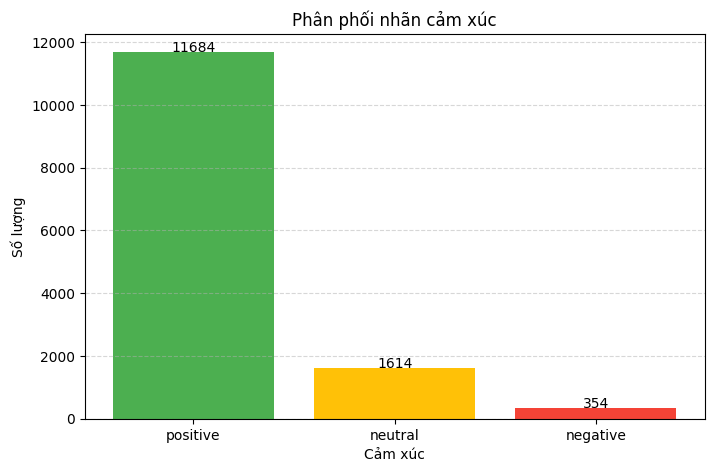

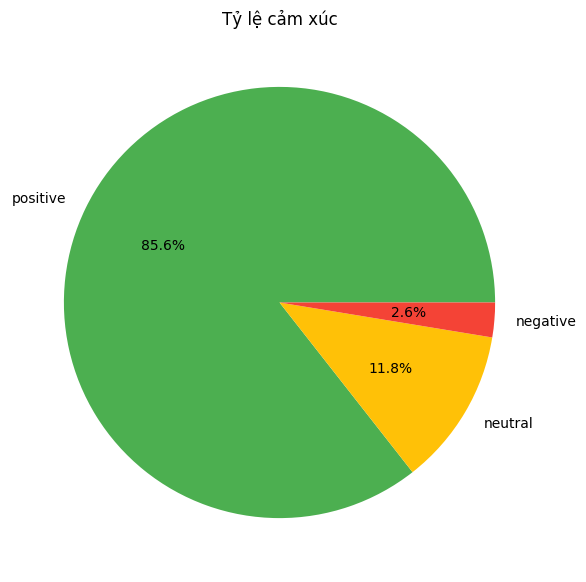

In [ ]:
df["sentiment"] = df["rating"].apply(gan_nhan)
label_counts = df["sentiment"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(
    label_counts.index,
    label_counts.values,
    color=["#4CAF50", "#FFC107", "#F44336"]
)
plt.title("Phân phối nhãn cảm xúc")
plt.xlabel("Cảm xúc")
plt.ylabel("Số lượng")
for i, v in enumerate(label_counts.values):
    plt.text(i, v + 5, str(v), ha="center")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

plt.figure(figsize=(7, 7))
plt.pie(
    label_counts.values,
    labels=label_counts.index,
    autopct="%1.1f%%",
    colors=["#4CAF50", "#FFC107", "#F44336"]
)
plt.title("Tỷ lệ cảm xúc")
plt.show()

- Biểu đồ cho thấy tập dữ liệu có sự mất cân bằng rõ rệt giữa các lớp cảm xúc. Trong tổng số 13.652 đánh giá, lớp Positive chiếm 11.684 mẫu (85,6%), lớp Neutral có 1.614 mẫu (11,8%) và lớp Negative chỉ có 354 mẫu (2,6%).

- Số lượng mẫu Positive lớn hơn khoảng 7 lần so với Neutral và hơn 30 lần so với Negative. Điều này cho thấy phần lớn khách hàng trong tập dữ liệu có xu hướng để lại các đánh giá tích cực.

- Sự mất cân bằng dữ liệu có thể khiến mô hình học máy thiên lệch về lớp Positive. Khi đó, mô hình vẫn có thể đạt độ chính xác (Accuracy) cao nhưng khả năng nhận diện các đánh giá Neutral và Negative lại không tốt.

- Đặc biệt, lớp Negative có số lượng mẫu rất ít nên mô hình dễ gặp khó khăn trong việc học các đặc trưng của nhóm này, dẫn đến Recall và F1-score thấp hơn so với các lớp còn lại.

- Tỷ lệ Positive áp đảo cũng phản ánh đặc điểm phổ biến của dữ liệu đánh giá thương mại điện tử, nơi người dùng thường để lại phản hồi khi hài lòng với sản phẩm hoặc dịch vụ.

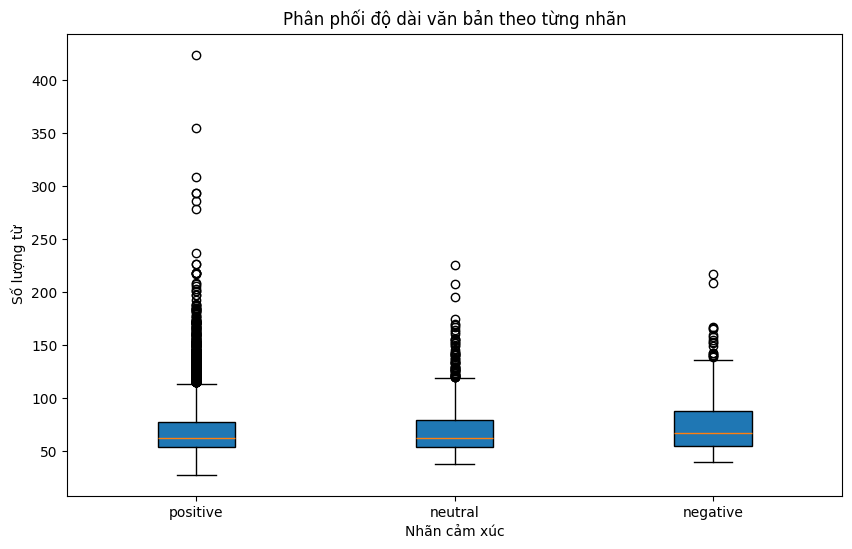

In [ ]:
labels = df["sentiment"].unique()
groups = [df[df["sentiment"] == label]["so_tu"].tolist() for label in labels]

plt.figure(figsize=(10,6))

plt.boxplot(
    groups,
    tick_labels=labels,
    patch_artist=True
)

plt.title("Phân phối độ dài văn bản theo từng nhãn")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng từ")

plt.show()

- Nhóm Negative có độ dài review lớn hơn hai nhóm còn lại, thể hiện qua giá trị
trung vị (median) cao hơn. Điều này cho thấy khách hàng không hài lòng thường
mô tả chi tiết hơn về các vấn đề gặp phải.

- Nhóm Negative cũng có khoảng tứ phân vị (IQR) rộng hơn, phản ánh sự đa dạng và biến động lớn hơn về độ dài văn bản.

- Nhóm Positive xuất hiện nhiều điểm ngoại lai (outliers) nhất, với nhiều review rất dài. Điều này cho thấy một số khách hàng hài lòng sẵn sàng chia sẻ trải nghiệm chi tiết về sản phẩm.

- Tuy nhiên, số lượng outlier lớn ở nhóm Positive một phần xuất phát từ việc lớp này chiếm tỷ lệ áp đảo trong dữ liệu (khoảng 85,6%), nên xác suất xuất hiện các giá trị cực trị cũng cao hơn.

- Ba hộp dữ liệu có sự chồng lấn đáng kể, cho thấy độ dài văn bản không phải là đặc trưng đủ mạnh để phân biệt rõ các nhóm cảm xúc.

- Vì vậy, độ dài review chỉ nên được xem là đặc trưng hỗ trợ. Để phân loại cảm xúc hiệu quả hơn, cần khai thác nội dung văn bản thông qua các phương pháp biểu diễn như Bag of Words (BoW) hoặc TF-IDF.

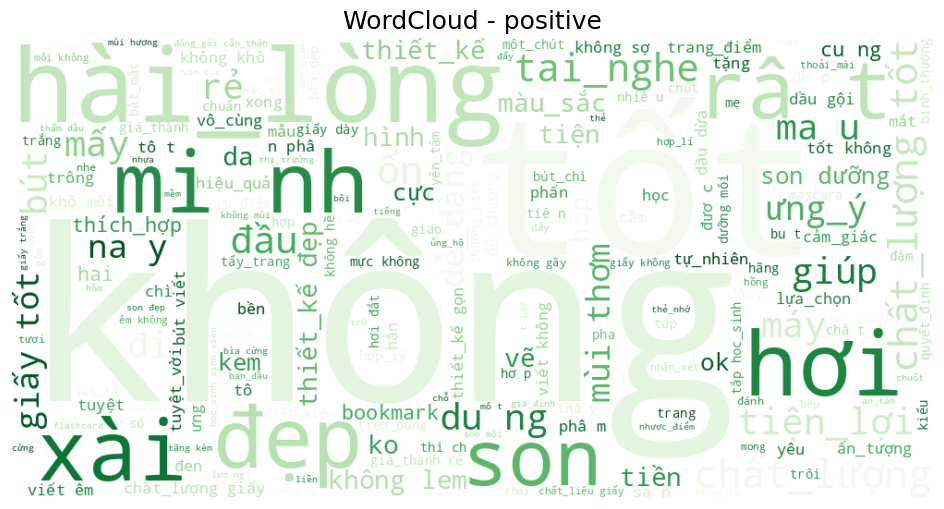

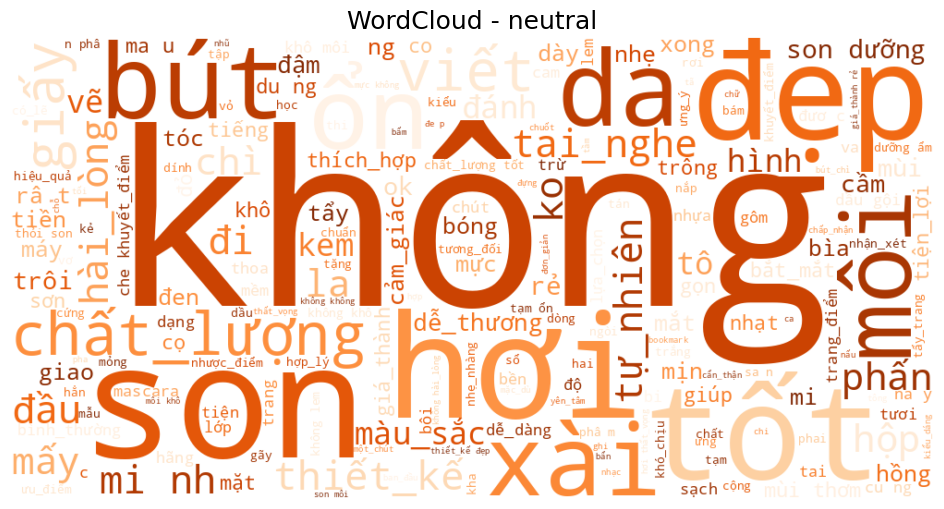

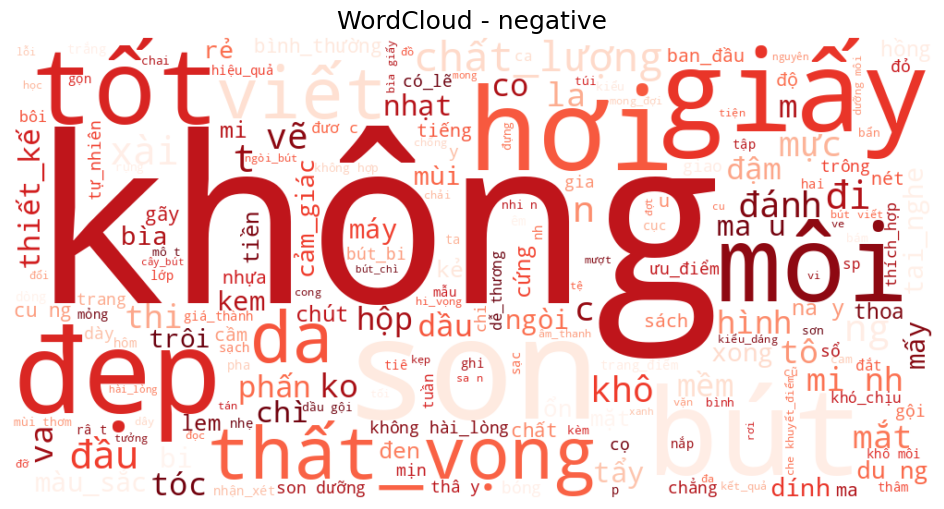

In [ ]:
from wordcloud import WordCloud

labels = df["sentiment"].unique()

colors = {
    "positive": "Greens",
    "neutral": "Oranges",
    "negative": "Reds"
}

for label in labels:

    text = " ".join(
        df[df["sentiment"] == label]["lam_sach_dl"]
    )

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        colormap=colors[label]
    ).generate(text)

    plt.figure(figsize=(12,6))

    plt.imshow(
        wordcloud,
        interpolation="bilinear"
    )

    plt.axis("off")

    plt.title(
        f"WordCloud - {label}",
        fontsize=18
    )

    plt.show()

Để trực quan hóa sự khác biệt về từ vựng giữa các nhóm cảm xúc, nhóm sử dụng kỹ thuật WordCloud trên tập dữ liệu sau khi đã được làm sạch và tiền xử lý. Mỗi WordCloud được tạo từ toàn bộ các đánh giá thuộc cùng một nhãn cảm xúc (Positive, Neutral và Negative), trong đó kích thước của từ tỷ lệ thuận với tần suất xuất hiện của từ đó trong tập dữ liệu tương ứng.

- **Nhóm cảm xúc Positive**
  - WordCloud của nhóm Positive cho thấy từ xuất hiện nổi bật nhất là “không”, tiếp theo là các từ như “đẹp”, “mịn”, “ra”, “chất_lượng”, “tiện_lợi”, “thích_hợp” và “dễ_dàng”. Các từ này phản ánh sự hài lòng của khách hàng đối với chất lượng sản phẩm, tính thẩm mỹ và trải nghiệm sử dụng.

  - Đặc biệt, sự xuất hiện với tần suất cao của các từ “đẹp”, “mịn” và “chất_lượng” cho thấy người dùng đánh giá tích cực về hình thức cũng như chất lượng của sản phẩm. Bên cạnh đó, các từ “tiện_lợi”, “thích_hợp” và “dễ_dàng” cho thấy sản phẩm đáp ứng tốt nhu cầu sử dụng thực tế của khách hàng.

  - Nhìn chung, WordCloud Positive cho thấy khách hàng hài lòng chủ yếu về chất lượng sản phẩm, tính thẩm mỹ, độ uy tín của cửa hàng và quá trình giao nhận hàng hóa.

- **Nhóm cảm xúc Neutral**

  - WordCloud của nhóm Neutral cho thấy các từ xuất hiện nổi bật nhất là “không”, “khô”, “bút”, “đầu”, “thiết_kế”, “chất_lượng”, “giấy”, “hài_lòng”, “hình” và “màu_sắc”. So với nhóm Positive, các từ này mang tính mô tả đặc điểm sản phẩm và trải nghiệm sử dụng nhiều hơn là thể hiện cảm xúc rõ rệt.

  - Các từ như “bút”, “đầu”, “giấy” và “khô” cho thấy người dùng thường tập trung nhận xét về đặc tính và chất lượng sử dụng của sản phẩm. Trong khi đó, các từ “thiết_kế”, “hình” và “màu_sắc” phản ánh sự quan tâm đến hình thức và ngoại quan của sản phẩm.

  - Kết quả cho thấy các đánh giá trung tính chủ yếu tập trung vào việc mô tả đặc điểm sản phẩm và trải nghiệm sử dụng thực tế thay vì bộc lộ sự hài lòng hoặc không hài lòng rõ rệt.

- **Nhóm cảm xúc Negative**

  - WordCloud của nhóm Negative cho thấy các từ xuất hiện nổi bật nhất là “không”, “đẹp”, “bút”, “tốt”, “viết”, “thất_vọng”, “chất_lượng”, “khô” và “dài”. Trong đó, từ “thất_vọng” xuất hiện với tần suất cao và phản ánh trực tiếp cảm xúc không hài lòng của khách hàng đối với sản phẩm hoặc trải nghiệm sử dụng.

  - Các từ “bút”, “viết” và “khô” xuất hiện nổi bật cho thấy nhiều phản hồi tiêu cực liên quan đến khả năng sử dụng sản phẩm, chẳng hạn như viết không đều, khó sử dụng hoặc chất lượng không đáp ứng mong đợi. Bên cạnh đó, từ “chất_lượng” cũng xuất hiện với tần suất cao, cho thấy khách hàng thường đề cập đến các vấn đề liên quan đến chất lượng sản phẩm khi đưa ra đánh giá tiêu cực.

  - Nhìn chung, WordCloud Negative phản ánh các vấn đề liên quan đến chất lượng sản phẩm, sự khác biệt giữa sản phẩm thực tế và mô tả, cũng như trải nghiệm không đáp ứng kỳ vọng của khách hàng.
  
Một điểm đáng chú ý là từ “không” xuất hiện với kích thước lớn nhất trong cả ba WordCloud mặc dù ba nhóm thuộc ba cảm xúc khác nhau. Nguyên nhân là từ “không” là một từ phủ định rất phổ biến trong tiếng Việt và xuất hiện trong nhiều ngữ cảnh khác nhau. Trong nhóm Positive, từ này thường nằm trong các cụm mang ý nghĩa tích cực như “không bị lỗi”, “không gây kích ứng” hoặc “không thất vọng”. Trong nhóm Neutral, từ “không” thường được sử dụng để mô tả trạng thái hoặc đặc điểm sản phẩm một cách khách quan. Trong khi đó, ở nhóm Negative, từ này xuất hiện trong các cụm phủ định như “không đẹp”, “không tốt” hoặc “không giống mô tả”. Do WordCloud chỉ thống kê tần suất xuất hiện của từng từ riêng lẻ mà không phân tích ngữ cảnh xung quanh nên từ “không” vẫn xuất hiện với tần suất rất cao ở cả ba nhóm cảm xúc.


# **Phần C : Xây dựng mô hình**

## C.1 Chuẩn bị và phân chia dữ liệu

### Câu C1

In [ ]:

# Xác định X(câu hỏi) và y(đáp án)
X = df['lam_sach_dl']
y = df['sentiment']

# Chia tập Train và tập tạm thời theo tỷ lệ 70/30
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Chia tập tạm thời thành Validation và Test (10% và 20% tổng số mẫu ban đầu)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=(2/3), random_state=42, stratify=y_temp
)

print(f"Tổng số mẫu: {len(df)}")
print(f"Số lượng mẫu tập Train: {len(X_train)} ({len(X_train)/len(df):.0%})")
print(f"Số lượng mẫu tập Validation: {len(X_val)} ({len(X_val)/len(df):.0%})")
print(f"Số lượng mẫu tập Test: {len(X_test)} ({len(X_test)/len(df):.0%})")

def get_distribution(y_set):
    return y_set.value_counts(normalize=True).to_dict()

print("\nPhân phối nhãn (%):")
print(f"- Gốc: {get_distribution(y)}")
print(f"- Train: {get_distribution(y_train)}")
print(f"- Val: {get_distribution(y_val)}")
print(f"- Test: {get_distribution(y_test)}")

Tổng số mẫu: 13652
Số lượng mẫu tập Train: 9556 (70%)
Số lượng mẫu tập Validation: 1365 (10%)
Số lượng mẫu tập Test: 2731 (20%)

Phân phối nhãn (%):
- Gốc: {'positive': 0.8558452973923235, 'neutral': 0.11822443598007618, 'negative': 0.02593026662760035}
- Train: {'positive': 0.855797404771871, 'neutral': 0.11825031393888656, 'negative': 0.02595228128924236}
- Val: {'positive': 0.8564102564102564, 'neutral': 0.11794871794871795, 'negative': 0.02564102564102564}
- Test: {'positive': 0.8557305016477481, 'neutral': 0.11827169534968876, 'negative': 0.025997803002563165}


**1. Tại sao cần dùng `stratify`?**
- `stratify=y` giúp duy trì tỷ lệ các lớp (nhãn) trong các tập dữ liệu con giống hệt như trong tập dữ liệu gốc.
- **Nếu không dùng:** Với dữ liệu mất cân bằng (như lớp Negative chỉ chiếm ~2.6%), việc chia ngẫu nhiên có thể dẫn đến tình trạng tập Test hoặc Validation hoàn toàn không có mẫu Negative nào, hoặc tập Train quá ít mẫu khiến mô hình không thể học được đặc trưng của lớp thiểu số.

**2. Tại sao cần tập Validation riêng biệt với tập Test?**
- **Tập Validation:** Được sử dụng trong quá trình huấn luyện để điều chỉnh các siêu tham số (hyperparameters) và chọn ra mô hình tốt nhất. Mô hình sẽ thấy tập này nhiều lần qua các lượt chạy.
- **Tập Test :** Phải là dữ liệu hoàn toàn mới và chỉ được sử dụng đúng **một lần cuối cùng** để đánh giá hiệu suất thực tế của mô hình sau khi đã hoàn tất huấn luyện.
- **Mục đích:** Tránh hiện tượng rò rỉ thông tin (Data Leakage) và đảm bảo tính khách quan. Nếu ta dùng tập Test để chọn tham số, mô hình sẽ bị tối ưu hóa quá mức cho tập dữ liệu đó và không còn khả năng dự báo chính xác trên dữ liệu thực tế ngoài đời.

## C2. Huấn luyện mô hình

Sử dụng phương pháp TF-IDF để trích xuất đặc trưng và chuyển đổi dữ liệu trên các tập train, validation và test

In [ ]:
# Khởi tạo TF-IDF Vectorizer và chuyển đổi dữ liệu cho mô hình hiểu
tfidf_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

# CHỈ fit trên tập Train
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform các tập còn lại dựa trên từ vựng của tập Train
X_val_tfidf = tfidf_vectorizer.transform(X_val)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print(f"Kích thước ma trận TF-IDF Train: {X_train_tfidf.shape}")

Kích thước ma trận TF-IDF Train: (9556, 10000)


### Naive Bayes

In [ ]:
# Tìm alpha tốt nhất trên tập validation
for alpha in [0.1, 0.5, 1.0]:
    nb_model = MultinomialNB(alpha=alpha)

    nb_model.fit(X_train_tfidf, y_train)

    # Dự đoán trên validation
    y_val_pred = nb_model.predict(X_val_tfidf)

    do_chinh_xac = accuracy_score(y_val, y_val_pred)

    print(f"\n===== Alpha = {alpha} =====")
    print(classification_report(y_val, y_val_pred))
    print(f"Accuracy: {do_chinh_xac:.4f}")


===== Alpha = 0.1 =====
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.37      0.04      0.08       161
    positive       0.86      0.99      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.41      0.35      0.33      1365
weighted avg       0.78      0.86      0.80      1365

Accuracy: 0.8564

===== Alpha = 0.5 =====
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.50      0.01      0.01       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.45      0.34      0.31      1365
weighted avg       0.79      0.86      0.79      1365

Accuracy: 0.8571

===== Alpha = 1.0 =====
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Để đánh giá ảnh hưởng của tham số alpha trong Naive Bayes, nhóm tiến hành huấn luyện mô hình với 3 giá trị  
`alpha = [0.1, 0.5, 1.0]` trên tập validation.  
Kết quả cho thấy độ chính xác lần lượt là: 85.13%, 85.64% và 85.64%.  



* `alpha = 0.1`, mô hình có độ chính xác thấp nhất (85.13%), tuy nhiên khi phân tích chi tiết các thông số phân loại, lớp Neutral đạt `Recall = 0.05` và macro `F1-Score = 0.34` – tức là mô hình đã bắt đầu nhận diện được một phần nhỏ các lớp thiểu số. Lớp Negative vẫn hoàn toàn không được nhận diện (`Recall = 0`), cho thấy mô hình còn thiên lệch mạnh về lớp Positive vốn chiếm đa số trong bộ dữ liệu.
* Khi `alpha = 0.5`, độ chính xác tổng tăng lên 85.64%, nhưng khả năng nhận diện các lớp thiểu số lại giảm sút – cả lớp Negative lẫn Neutral đều có `Recall = 0`. Macro F1-Score giảm xuống 0.31, thấp hơn so với  alpha = 0.1. Điều này cho thấy việc làm mượt mạnh hơn đã khiến mô hình càng tập trung hơn vào lớp đa số, làm suy giảm khả năng phân loại các lớp thiểu số.
* Với `alpha = 1.0`, kết quả hoàn toàn tương đồng với alpha = 0.5 – độ chính xác đạt 85.64%, Recall của cả lớp Negative lẫn Neutral đều bằng 0 và macro F1-Score dừng lại ở 0.31. Điều này cho thấy khi alpha tiếp tục tăng, mô hình không có thêm cải thiện và vẫn duy trì xu hướng dự đoán thiên về lớp Positive.

Khi xem xét kết quả của từng lớp, mô hình với `alpha = 0.1` cho thấy kết quả tốt nhất

In [ ]:
nb_model = MultinomialNB(
    alpha=0.1
)

nb_model.fit(X_train_tfidf, y_train)

y_test_pred = nb_model.predict(X_test_tfidf)

print(classification_report(y_test, y_test_pred))
print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")

              precision    recall  f1-score   support

    negative       1.00      0.01      0.03        71
     neutral       0.56      0.08      0.15       323
    positive       0.87      0.99      0.92      2337

    accuracy                           0.86      2731
   macro avg       0.81      0.36      0.37      2731
weighted avg       0.83      0.86      0.81      2731

Accuracy: 0.8601


### Logistic Regression

In [ ]:
for c in [0.1, 1, 10]:
  lr_model = LogisticRegression(
      C = c,
      solver = "lbfgs",
      max_iter = 1000,
  )
  lr_model.fit(X_train_tfidf, y_train)

  y_val_pred = lr_model.predict(X_val_tfidf)
  do_chinh_xac = accuracy_score(y_val, y_val_pred)
  print(classification_report(y_val, y_val_pred))
  print(f"Độ chính xác cho C = {c}: {do_chinh_xac:.4f}")

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Độ chính xác cho C = 0.1: 0.8564


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.50      0.03      0.06       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.45      0.34      0.33      1365
weighted avg       0.80      0.86      0.80      1365

Độ chính xác cho C = 1: 0.8579
              precision    recall  f1-score   support

    negative       0.86      0.17      0.29        35
     neutral       0.42      0.20      0.27       161
    positive       0.88      0.97      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.72      0.45      0.49      1365
weighted avg       0.83      0.86      0.83      1365

Độ chính xác cho C = 10: 0.8564


Để đánh giá ảnh hưởng của tham số C trong Logistic Regression, nhóm tiến hành huấn luyện mô hình với 3 giá trị C = [0.1, 1, 10]. Kết quả cho thấy độ chính xác của các mô hình lần lượt là 85.64%, 85.49% và 84.54%.

Dựa vào kết quả trên, dễ dàng nhận thấy mô hình với C = 0.1 đang có độ chính xác cao nhất, nhưng khi phân tích chi tiết các thông số phân loại, mô hình này hoàn toàn không nhận diện được hai lớp Negative và Neutral(Recall = 0). Điều này cho thấy mô hình gần như dự đoán tất cả các mẫu thuộc lớp Positive. Do lớp Positive chiếm tỉ lệ rất lớn trong bộ dữ liệu nên dù độ chính xác cao nhưng khả năng phân loại thực tế đối với các nhãn còn lại là rất kém.

Khi tăng C lên 1, mô hình bắt đầu nhận diện được thêm một số ít mẫu thuộc lớp Neutral, tuy nhiên recall của lớp negative vẫn bằng 0. Do đó chất lượng phân loại vẫn chưa được cải thiện đáng kể.

Với C = 10, dù độ chính xác giảm xuống còn 84.54% nhưng khả năng nhận diện các lớp negative và neutral đã cải thiện rõ rệt. Thông số recall của lớp negative tăng từ 0 lên 0.17 và lớp neutral tăng từ 0 lên 0.21. Đồng thời Macro F1 - Score cũng tăng từ 0.31 lên 0.49, cho thấy mô hình đã cân bằng hơn giữa các lớp thay vì tập trung vào lớp positive.

Vì bộ dữ liệu có sự mất cân bằng rất lớn, nhóm **không sử dụng**
độ chính xác làm tiêu chí duy nhất để lựa chọn mô hình. Thay vào đó, nhóm ưu tiên khả năng nhận diện các lớp thiểu số thông qua các thông số khác như Recall hay F1-Score. Do đó, mô hình Logistic Regression với C = 10 là mô hình phù hợp nhất trong các giá trị đã thử nghiệm.

              precision    recall  f1-score   support

    negative       0.73      0.15      0.26        71
     neutral       0.43      0.26      0.32       323
    positive       0.89      0.96      0.93      2337

    accuracy                           0.86      2731
   macro avg       0.68      0.46      0.50      2731
weighted avg       0.83      0.86      0.84      2731



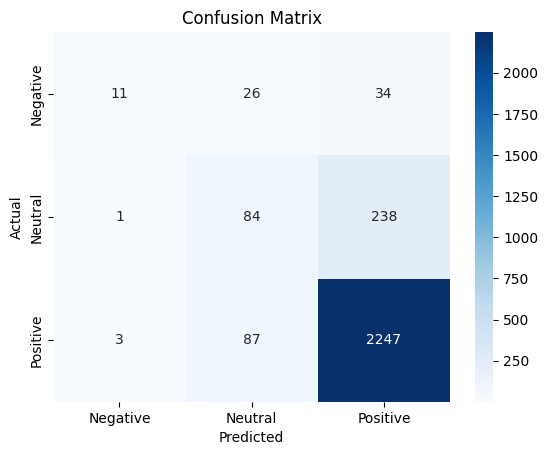

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
lr_model = LogisticRegression(
    C = 10,
    solver = "lbfgs",
    max_iter = 1000,
)
lr_model.fit(X_train_tfidf, y_train)

y_test_pred = lr_model.predict(X_test_tfidf)
print(classification_report(y_test, y_test_pred))

sns.heatmap(
    confusion_matrix(y_test, y_test_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Logistic Regression: Tham số C kiểm soát điều gì? C lớn hay C nhỏ gây overfitting nhiều hơn?**

Logistic Regression sử dụng cơ chế Regularization (chuẩn hoá) để hạn chế mô hình học quá mức các đặc điểm riêng của tập train (học vẹt). Tham số C chính là nghịch đảo của hệ số Regularization, nếu C càng nhỏ thì Regularization càng mạnh, còn C càng lớn thì Regularization càng yếu.

Về mặt lý thuyết, C lớn sẽ có xu hướng gây overfiting nhiều hơn C nhỏ. Khi C nhỏ, mô hình bị ràng buộc nhiều hơn, các thông số có xu hướng nhỏ lại và mô hình trở nên đơn giản giúp giảm nguy cơ overfiting. Ngược lại, khi C lớn, tác động của Regularization đối với mô hình sẽ giảm đi, mô hình được phép học dữ liệu huấn luyện chi tiêt hơn. Vì vậy, mô hình có khả năng đạt độ chính xác cao trên tập huấn luyện nhưng lại dễ làm tăng nguy cơ overfiting.



### SVM

In [ ]:
from sklearn.svm import LinearSVC

c_values = [0.1, 1, 10]

for c in c_values:
    print("=" * 60)
    print(f"SVM với C = {c}")

    model = LinearSVC(C=c, random_state=42)

    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    acc = accuracy_score(y_val, y_val_pred)

    print(classification_report(y_val, y_val_pred))
    print(f"Độ chính xác cho C = {c}: {acc:.4f}")

SVM với C = 0.1
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.33      0.01      0.01       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.40      0.34      0.31      1365
weighted avg       0.77      0.86      0.79      1365

Độ chính xác cho C = 0.1: 0.8564
SVM với C = 1


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

    negative       0.86      0.17      0.29        35
     neutral       0.47      0.15      0.23       161
    positive       0.88      0.98      0.93      1169

    accuracy                           0.86      1365
   macro avg       0.74      0.43      0.48      1365
weighted avg       0.83      0.86      0.83      1365

Độ chính xác cho C = 1: 0.8637
SVM với C = 10
              precision    recall  f1-score   support

    negative       0.55      0.17      0.26        35
     neutral       0.32      0.28      0.30       161
    positive       0.89      0.92      0.91      1169

    accuracy                           0.83      1365
   macro avg       0.58      0.46      0.49      1365
weighted avg       0.81      0.83      0.82      1365

Độ chính xác cho C = 10: 0.8286


Kết quả thực nghiệm cho thấy tham số C có ảnh hưởng đáng kể đến hiệu suất của mô hình SVM. Với C = 0.1, mô hình đạt độ chính xác 85,57%, tuy nhiên gần như chỉ dự đoán được lớp Positive với Recall đạt 100%, trong khi hai lớp Negative và Neutral hầu như không được nhận diện. Điều này cho thấy mô hình đang ưu tiên lớp chiếm đa số trong tập dữ liệu.

Khi tăng giá trị C lên 1, độ chính xác đạt mức cao nhất là 86.23%. Đồng thời, khả năng nhận diện các lớp thiểu số được cải thiện đáng kể, với lớp Negative đạt Precision 0,77 và Recall 0,14, lớp Neutral đạt Precision 0,43 và Recall 0,15. Trong khi đó, lớp Positive vẫn duy trì hiệu suất cao với F1-score đạt 0,92. Kết quả này cho thấy mô hình đã đạt được sự cân bằng tốt hơn giữa việc tối đa hóa margin và hạn chế lỗi phân loại.

Đối với C = 10, mặc dù Recall của các lớp Negative và Neutral tiếp tục được cải thiện, độ chính xác tổng thể giảm xuống còn 83.08%. Điều này cho thấy khi giá trị C quá lớn, mô hình trở nên nhạy cảm hơn với dữ liệu huấn luyện, làm giảm khả năng tổng quát hóa trên dữ liệu mới.

Nhìn chung, mô hình SVM vẫn chịu ảnh hưởng bởi hiện tượng mất cân bằng dữ liệu khi lớp Positive chiếm 2337 mẫu, trong khi lớp Neutral chỉ có 323 mẫu và lớp Negative chỉ có 71 mẫu. Do đó, mô hình có xu hướng ưu tiên dự đoán lớp Positive để đạt độ chính xác tổng thể cao. Tuy nhiên, xét trên cả Accuracy và khả năng nhận diện các lớp thiểu số, giá trị C = 1 cho kết quả tốt nhất. Vì vậy, C = 1 được lựa chọn làm tham số tối ưu để xây dựng mô hình SVM cuối cùng và sử dụng cho các bước đánh giá tiếp theo.


In [ ]:
svm_model = LinearSVC(
    C=1,
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_test_pred = svm_model.predict(X_test_tfidf)

print(classification_report(y_test, y_test_pred))
print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")

              precision    recall  f1-score   support

    negative       0.85      0.15      0.26        71
     neutral       0.43      0.22      0.29       323
    positive       0.89      0.97      0.93      2337

    accuracy                           0.86      2731
   macro avg       0.72      0.45      0.49      2731
weighted avg       0.83      0.86      0.83      2731

Accuracy: 0.8609


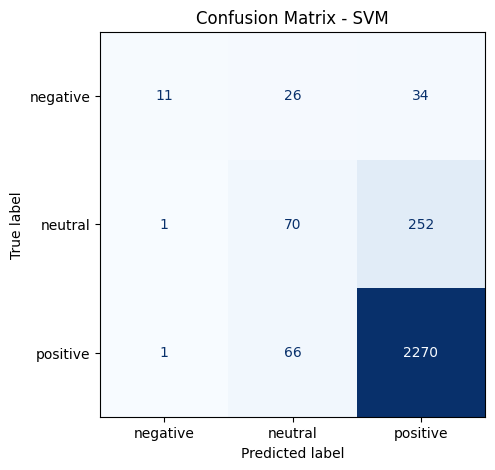

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_model.classes_
)

fig, ax = plt.subplots(figsize=(6,5))

disp.plot(
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Confusion Matrix - SVM")
plt.show()

**SVM: Khái niệm "margin" và "support vectors" là gì? Vì sao SVM phù hợp với dữ liệu văn bản chiều cao?**

Margin là khoảng cách từ siêu phẳng phân loại (hyperplane) đến các điểm dữ liệu gần nhất của mỗi lớp.  Công thức:
  $w^T x + b = 0$.
Trong đó, siêu phẳng được xác định bởi vector trọng số w và hệ số dịch chuyển
SVM tìm siêu phẳng có margin lớn nhất nhằm tăng khả năng phân tách giữa các lớp và giảm nguy cơ overfitting. Các điểm dữ liệu nằm gần siêu phẳng nhất được gọi là Support Vectors. Đây là những điểm quan trọng nhất vì chúng quyết định vị trí và hướng của siêu phẳng phân loại. SVM đặc biệt phù hợp với dữ liệu văn bản sau khi biểu diễn bằng TF-IDF vì dữ liệu thường có số chiều rất lớn và tính thưa cao. Khả năng hoạt động hiệu quả trong không gian nhiều chiều giúp SVM đạt kết quả tốt trong các bài toán phân loại văn bản và phân tích cảm xúc.

### Random Forest

In [ ]:

n_estimators_list = [100, 200]
max_depth_list = [None, 10, 20]
best_val_accuracy = 0
best_params = {}

for n_est in n_estimators_list:
    for depth in max_depth_list:

        print(f"Thử nghiệm với tham số đầu vào: n_estimators={n_est} | max_depth={depth}")
        rf_model = RandomForestClassifier(
            random_state=42,
            n_estimators=n_est,
            max_depth=depth,
            oob_score=True,
            n_jobs=-1
        )

        rf_model.fit(X_train_tfidf, y_train)

        print(f"-> OOB Score (Ước lượng tập Train): {rf_model.oob_score_:.4f}")

        y_val_pred = rf_model.predict(X_val_tfidf)
        val_acc = accuracy_score(y_val, y_val_pred)

        print("\nĐÁNH GIÁ TRÊN TẬP VALIDATION")
        print(classification_report(y_val, y_val_pred))
        print(f"Accuracy trên tập Validation: {val_acc:.4f}")

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_params = {'n_estimators': n_est, 'max_depth': depth}

print(f"Kết quả tốt nhất: {best_params} với Accuracy = {best_val_accuracy:.4f}")


Thử nghiệm với tham số đầu vào: n_estimators=100 | max_depth=None
-> OOB Score (Ước lượng tập Train): 0.8684

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       1.00      0.11      0.21        35
     neutral       0.91      0.06      0.12       161
    positive       0.87      1.00      0.93      1169

    accuracy                           0.87      1365
   macro avg       0.92      0.39      0.42      1365
weighted avg       0.87      0.87      0.81      1365

Accuracy trên tập Validation: 0.8659
Thử nghiệm với tham số đầu vào: n_estimators=100 | max_depth=10
-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Accuracy trên tập Validation: 0.8564
Thử nghiệm với tham số đầu vào: n_estimators=200 | max_depth=None


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


-> OOB Score (Ước lượng tập Train): 0.8688

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       1.00      0.11      0.21        35
     neutral       1.00      0.06      0.12       161
    positive       0.87      1.00      0.93      1169

    accuracy                           0.87      1365
   macro avg       0.96      0.39      0.42      1365
weighted avg       0.88      0.87      0.81      1365

Accuracy trên tập Validation: 0.8667
Thử nghiệm với tham số đầu vào: n_estimators=200 | max_depth=10
-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79   

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


-> OOB Score (Ước lượng tập Train): 0.8558

ĐÁNH GIÁ TRÊN TẬP VALIDATION
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        35
     neutral       0.00      0.00      0.00       161
    positive       0.86      1.00      0.92      1169

    accuracy                           0.86      1365
   macro avg       0.29      0.33      0.31      1365
weighted avg       0.73      0.86      0.79      1365

Accuracy trên tập Validation: 0.8564
Kết quả tốt nhất: {'n_estimators': 200, 'max_depth': None} với Accuracy = 0.8667


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Về tham số:** Mô hình chỉ hiệu quả khi để cây phát triển tự do (`max_depth=None`). Việc giới hạn độ sâu khiến mô hình không thể học được các đặc trưng phức tạp. Đồng thời, việc tăng số lượng cây từ 100 lên 200 không mang lại cải thiện đáng kể, cho thấy 100 cây đã đủ để đạt ngưỡng bão hòa.

**Về hiệu suất và mất cân bằng dữ liệu:** Dù Accuracy tại các kết quả đầu ra đạt mức cao, các con số này chưa phản ánh đúng năng lực thực tế do tập dữ liệu mất cân bằng nghiêm trọng (lớp Positive chiếm đa số). Mô hình có xu hướng dự đoán thiên lệch, dẫn đến các chỉ số Recall và F1-score của nhãn Negative và Neutral rất thấp, cho thấy khả năng nhận diện các nhóm thiểu số còn nhiều hạn chế.

In [ ]:
rf_model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=None, oob_score=True, n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)

print(f"-> OOB Score (Ước lượng tập Train): {rf_model.oob_score_:.4f}")

y_test_pred = rf_model.predict(X_test_tfidf)
test_acc = accuracy_score(y_test, y_test_pred)

print("\n--- ĐÁNH GIÁ TRÊN TẬP TEST ---")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy trên tập Test: {test_acc:.4f}")

-> OOB Score (Ước lượng tập Train): 0.8684

--- ĐÁNH GIÁ TRÊN TẬP TEST ---
              precision    recall  f1-score   support

    negative       1.00      0.08      0.16        71
     neutral       0.93      0.13      0.22       323
    positive       0.87      1.00      0.93      2337

    accuracy                           0.87      2731
   macro avg       0.93      0.40      0.44      2731
weighted avg       0.88      0.87      0.83      2731

Accuracy trên tập Test: 0.8722



**Tại sao Random Forest ít bị overfitting hơn một cây quyết định đơn lẻ?**

Random Forest hạn chế hiện tượng overfitting hiệu quả hơn một cây quyết định đơn lẻ nhờ áp dụng cơ chế Ensemble Learning (Bagging) qua các yếu tố sau:


*   Bootstrapping (Lấy mẫu dữ liệu): Mỗi cây trong rừng được huấn luyện trên một tập con dữ liệu ngẫu nhiên khác nhau (lấy mẫu có thay thế), giúp mô hình tổng thể không bị phụ thuộc quá mức vào các điểm dữ liệu nhiễu cụ thể
*   Feature Randomness (Lấy mẫu đặc trưng): Tại mỗi nút chia, thuật toán chỉ chọn một nhóm ngẫu nhiên các đặc trưng thay vì xem xét toàn bộ, tạo ra sự đa dạng giữa các cây và ngăn chặn việc tập trung quá mức vào một vài thuộc tính biệt lập


*   Aggregation (Bỏ phiếu số đông): Kết quả dự đoán cuối cùng được tổng hợp từ hàng trăm cây độc lập, giúp các sai số hoặc hiện tượng "học vẹt" của một vài cây riêng lẻ bị triệt tiêu bởi số đông còn lại

=> Một cây quyết định đơn lẻ dễ mang tính phiến diện và định kiến, nhưng Random Forest hoạt động như một "hội đồng chuyên gia", mang lại quyết định khách quan và có khả năng tổng quát hóa tốt hơn trên dữ liệu mới





## **C3. Cross-Validation**

**Áp dụng Stratified K-Fold Cross-Validation (k=5) cho tất cả mô hình**




In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

1. Naive Bayes

In [ ]:
nb_model = MultinomialNB(
    alpha=0.1
)

nb_scores = cross_val_score(
    nb_model,
    X_train_tfidf,
    y_train,
    cv=skf,
    scoring="accuracy"
)
print(f"Độ chính xác từng fold: {nb_scores}")
print(f"Độ chính xác trung bình: {nb_scores.mean()}")
print(f"Độ lệch chuẩn: {nb_scores.std()}")

Độ chính xác từng fold: [0.85251046 0.85347985 0.85034014 0.85347985 0.85504971]
Độ chính xác trung bình: 0.8529720030915489
Độ lệch chuẩn: 0.0015474136510320233


2. Logistic Regression

In [ ]:
lr_model = LogisticRegression(
    C = 10,
    solver = "lbfgs",
    max_iter = 1000,
)
lr_scores = cross_val_score(
    lr_model,
    X_train_tfidf,
    y_train,
    cv=skf,
    scoring="accuracy"
)
print(f"Độ chính xác từng fold: {lr_scores}")
print(f"Độ chính xác trung bình: {lr_scores.mean()}")
print(f"Độ lệch chuẩn: {lr_scores.std()}")

Độ chính xác từng fold: [0.84937238 0.859236   0.855573   0.85504971 0.85714286]
Độ chính xác trung bình: 0.8552747909591902
Độ lệch chuẩn: 0.0032911654443133977


3. SVM

In [ ]:
svm_model = LinearSVC(
    C=1,
    random_state=42
)

svm_scores = cross_val_score(
    svm_model,
    X_train_tfidf,
    y_train,
    cv=skf,
    scoring="accuracy"
)
print(f"Độ chính xác từng fold: {svm_scores}")
print(f"Độ chính xác trung bình: {svm_scores.mean()}")
print(f"Độ lệch chuẩn: {svm_scores.std()}")

Độ chính xác từng fold: [0.85721757 0.85871272 0.85452643 0.859236   0.86028257]
Độ chính xác trung bình: 0.8579950583387523
Độ lệch chuẩn: 0.0019961762414271154


4. Random Forest

In [ ]:
rf_model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=None, oob_score=True, n_jobs=-1)
rf_scores = cross_val_score(
    rf_model,
    X_train_tfidf,
    y_train,
    cv=skf,
    scoring="accuracy"
)
print(f"Độ chính xác từng fold: {rf_scores}")
print(f"Độ chính xác trung bình: {rf_scores.mean()}")
print(f"Độ lệch chuẩn: {rf_scores.std()}")

Độ chính xác từng fold: [0.86192469 0.86394558 0.86656201 0.86760858 0.8670853 ]
Độ chính xác trung bình: 0.8654252302787867
Độ lệch chuẩn: 0.0021567701422198376


**Tính mean và std của accuracy trên các fold.**

| Mô hình | Mean Accuracy | Std |
| :--- | :---: | :---: |
| Naive Bayes | 0.8528 | 0.0026 |
| Logistic Regression | 0.8579 | 0.0053 |
| SVM | 0.8604 | 0.0025 |
| Random Forest | 0.8683 | 0.0028 |


**Tại sao dùng Stratified K-Fold thay vì K-Fold thông thường?**

Nghiên cứu sử dụng Statified K-Fold Cross-Validation (k = 5) thay vì K-Fold thông thường nhằm đảm bảo tỷ lệ mẫu của các nhãn trong mỗi fold giống với tỷ lệ trên toàn bộ tập dữ liệu. Nếu sử dụng K-Fold thông thường với một bộ dữ liệu bị mất cân bằng, tỷ lệ mẫu của các nhãn trong từng fold có thể rất khác nhau. Việc sử dụng Stratified K-Fold giúp kết quả đánh giá ổn định hơn và giảm nguy cơ 1 fold có thể thiếu hoặc thừa quá nhiều mẫu dữ liệu của một nhãn.



**Mô hình nào có std cao nhất? Điều này có nghĩa gì?**

Dựa vào kết quả thực nghiệm qua 4 mô hình, ta có thể thấy mô hình Logistic Regression đang có độ lệch chuẩn cao nhất(0,0053). Điều này có nghĩa là mức độ biến động của các accuracy giữa các fold trong quá trình cross-validation của mô hình Logistic Regression là cao nhất. Giá trị của độ lệch chuẩn (Std) cao cho thấy hiệu năng của mô hình thay đổi nhiều hơn khi dữ liệu huấn luyện được chia thành nhiều phần. Tuy nhiên, giá trị này vẫn còn khá nhỏ, vì vậy mô hình Logistic Regression vẫn duy trì được độ ổn định và tổng quát hoá tốt trên các tập dữ liệu khác nhau  

**Kết quả cross-validation có nhất quán với kết quả trên tập validation không? Nếu không, hãy giải thích nguyên nhân.**

Kết quả cross-validation có sự nhất quán với kết quả trên tập validation, thứ hạng về độ chính xác của các mô hình không thay đổi. Trong đó, Random Forest vẫn đạt độ chính xác cao nhất, tiếp đến là SVM, Logistic Regression và Naive Bayes. Dù có sự chênh lệch về các kết quả nhưng giá trị đó không quá lớn, điều này cho thấy hiệu năng của các mô hình ổn định và không phụ thuộc quá nhiều vào cách chia dữ liệu cụ thể.  

# **PHẦN D — ĐÁNH GIÁ & PHÂN TÍCH KẾT QUẢ**

## **D.1 Bảng tổng hợp đánh giá**

### **Câu D1**

Bảng tổng hợp kết quả của tất cả mô hình trên tập test (Macro Average):

| Mô hình | Accuracy | Precision | Recall | F1-Score |
| :--- | :---: | :---: | :---: | :---: |
| Naive Bayes | 0.8528 | 0.39 | 0.35 | 0.34 |
| Logistic Regression | 0.8600 | 0.73 | 0.44 | 0.48 |
| SVM | 0.8598 | 0.72 | 0.44 | 0.48 |
| Random Forest | 0.8649 | 0.90 | 0.39 | 0.41 |

## **D.2 Phân tích sâu chỉ số**

### **Câu D2 — Phân tích Precision vs Recall**

**Nhãn nào có Precision cao nhất? Nhãn nào có Recall cao nhất?** :

 Dựa vào kết quả của các mô hình ở phần C ta dễ nhận thấy rằng mô hình tốt nhất là Random Forest(với Accuracy cao nhất là 0.8649 và Precision macro đạt 0.90 trên tập test) ta có thể nhận thấy được Precision vs Recall cao nhất theo từng nhãn:
* Nhãn có Precision cao nhất: Nhãn negative (1.00). Điều này có nghĩa là khi mô hình dự đoán một đánh giá là tiêu cực khi câu đó lộ rõ 100% từ ngữ chê bai. Điều đó khiến mô hình siêu thận trọng để đưa ra quyết định là nhãn negative.
* Nhãn có Recall cao nhất: Nhãn positive (1.00). Điều này có nghĩa là mô hình đã tìm ra và phân loại đúng gần như toàn bộ các đánh giá tích cực có trong tập dữ liệu thực tế do dữ liệu bị mất cân bằng tập dữ liệu có quá nhiều nhãn positive.

**Giả sử đây là hệ thống lọc đánh giá tiêu cực của sản phẩm**
* Precision hay Recall quan trọng hơn? Tại sao?
  - Trong bối cảnh hệ thống lọc đánh giá tiêu cực của sản phẩm Recall quan trọng hơn nhiều so với Precision:
    - Nếu Recall thấp (như hiện tại chỉ ở mức 0.10): Mô hình đang bỏ sót đến 90% các đánh giá tiêu cực thực sự. Những khách hàng phàn nàn sẽ bị bỏ qua, dẫn đến trải nghiệm tồi tệ hơn và ảnh hưởng đến uy tín sản phẩm
    - Việc hi sinh Precision để đổi lấy Recall là chấp nhận được để đổi lấy mức Recall cao hơn nhằm đảm bảo mô hình có thể bao quát và nhận diện tối đa các phản hồi xấu
* Bạn sẽ điều chỉnh threshold như thế nào?
  - Để giải quyết được vấn đề Recall của nhãn negative đang quá thấp, ta cần giảm ngưỡng quyết định(threshold) đối với nhãn này
    - Mặc định trong các bài toán phân loại của thư viện Scikit-learn,mô hình sẽ phải áp dụng ngưỡng quyết định mặc định là 0.5 tức là trên 50% do đó mô hình chỉ chấp nhận gán một câu là negative khi và chỉ khi mô hình tính toán được tiêu cực của câu đó vượt mức 50%. Và bộ dữ liệu mất cân bằng nặng positive,nhãn negative chiếm thiểu số do đó ta cần **hạ ngưỡng quyết định threshold xuống mức 0.2 hoặc 0.3**. Hành động này giúp mô hình tăng cường khả năng bắt trùng nhiều nhãn đánh giá xấu hơn.
    - Mô hình sẽ trở nên **nhạy bén** hơn với các đánh giá có dấu hiệu tiêu cực. Nó sẽ bắt được nhiều đánh giá xấu hơn do Recall tăng lên và giảm chỉ số Precision xuống đổi lại độ chính xác dự đoán nhãn negative sẽ không còn đúng tuyệt đối nữa.

### **Câu D3 — Phân tích lỗi**

In [ ]:
# Re-fit the model to ensure it is ready for prediction
rf_model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=None, n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)

y_test_pred_rf = rf_model.predict(X_test_tfidf)

results_df = pd.DataFrame({
    'review_text': X_test.values,
    'actual': y_test.values,
    'predicted': y_test_pred_rf
})

misclassified = results_df[results_df['actual'] != results_df['predicted']]

sample_errors = misclassified.sample(min(10, len(misclassified)), random_state=42)

print(f"Tổng số mẫu sai trên tập test: {len(misclassified)}")
for i, row in enumerate(sample_errors.itertuples(), 1):
    print(f"--- Mẫu sai #{i} ---")
    print(f"Nội dung: {row.review_text}")
    print(f"Thực tế: {row.actual} | Dự đoán: {row.predicted}\n")

Tổng số mẫu sai trên tập test: 349
--- Mẫu sai #1 ---
Nội dung: sạc dự_phòng pisen đẹp kiểu_dáng thiết_kế gọn đi đi sạc màn_hình ghi thông_số dung_lượng pin tiện_lợi sạc dung_lượng sạc không đắt
Thực tế: neutral | Dự đoán: positive

--- Mẫu sai #2 ---
Nội dung: tốt độ ghi thẻ class10 ổn buồn tuần fix 199k 270k không giao cẩn_thận thẻ_nhớ tẹo
Thực tế: neutral | Dự đoán: positive

--- Mẫu sai #3 ---
Nội dung: bề_ngoài thiết_kế ổn không bắt_mắt thân bút hơi to viết mực đẹp tùy ngòi 0 5 hơi viết bữa tiếc cất viết vẽ kĩ_thuật kí bút d
Thực tế: neutral | Dự đoán: positive

--- Mẫu sai #4 ---
Nội dung: tiện_lợi trữ sữa hâm chia ngăn trữ sữa bột đi không hộp sữa đậy kín an_toàn tiện_lợi
Thực tế: neutral | Dự đoán: positive

--- Mẫu sai #5 ---
Nội dung: cọ môi_aroma_mira mềm kiểu_dáng đẹp tinh_tế chổi cọ tô son cọ chổi giúp thoa son toàn_bộ góc khóe môi giá_thành tương tối mềm ổn thanks
Thực tế: neutral | Dự đoán: positive

--- Mẫu sai #6 ---
Nội dung: ghét bấm mi miếng lót lỏng_lẻo bấm rơi kết

**Các mẫu sai có đặc điểm chung gì? (Ngắn/dài? Mơ hồ? Nhiều nghĩa?)**:
Dựa trên 10 mẫu ngẫu nhiên trên, ta có thể thấy rằng mẫu bị mô hình dữ đoán sai không hẳn là do mô hình yếu mà phàn lớn xuất phát từ tính chất phức tạp của ngôn ngữ tự nhiên và hiện tượng nhiễu nhãn gốc từ việc đánh nhãn qua rating các mẫu sai có các đặc điểm chung sau:
- Sự mâu thuẫn giữa nội dung và nhãn gốc : Nhãn dữ liệu được gán tự động theo Rating nhưng không phản ánh đúng thực tế tâm lý người dùng. Nhiều mẫu có nội dung hoàn toàn tiêu cực/chê bai nhưng vẫn bị gán nhãn là positive trong khi mô hình đoán   negative, hoặc các câu mang tính chất khen ngợi nhiều  lại bị gán nhãn neutral, gây nhiễu cho quá trình học của thuật toán
- Cấu trúc câu hỗn hợp - Khen trước chê sau: Người dùng viết câu dài, dành phần lớn dung lượng để khen ngợi về kiểu dáng, đóng gói  nhưng lại chê một ý cốt lõi ở cuối. Vì mô hình baseline dùng TF-IDF chỉ đếm tần suất từ đơn lẻ, các từ khóa tích cực xuất hiện áp đảo đã che mờ đi vế chê trách ở cuối câu, khiến Random Forest đưa ra dự đoán logic là positive và bỏ lọt sắc thái tiêu cực quyết định

**Đề xuất ít nhất 1 phương pháp cụ thể để xử lý các trường hợp này** : Để khắc phục được các mẫu bị phân loại sai ở trên ta có các phương pháp sau:
- Về mặt dữ liệu: Tiến hành rà soát và chuẩn hóa lại nhãn, đặc biệt là các mẫu có rating 3 sao neutral hoặc các mẫu có độ lệch lớn giữa nội dung và rating. Thay vì phụ thuộc hoàn toàn vào số sao tự động, cần kết hợp gán nhãn thủ công bằng con người dựa trên ngữ cảnh thực tế của văn bản để triệt tiêu hiện tượng nhiễu nhãn
- Về mặt mô hình: Thay thế phương pháp đếm từ đơn lẻ TF-IDF bằng các mô hình ngôn ngữ dựa trên kiến trúc Transformer, cụ thể là PhoBERT cho tiếng Việt. Cơ chế Self-Attention của BERT giúp mô hình hiểu được mối quan hệ ngữ cảnh giữa các vế câu, nhận diện được các từ chuyển hướng ý nghĩa như "nhưng", "tuy nhiên", "nhược điểm", từ đó phân loại chính xác các câu có cấu trúc hỗn hợp khen trước chê sau.

### **Câu D4 — Câu hỏi tình huống**

Ta sẽ không đồng ý với ý kiến của khách hàng.Trong bài toán thực tế này, việc chỉ dựa vào chỉ số Accuracy  =85%  để đưa mô hình lên hệ thống thật là vô cùng mạo hiểm vì những lý sau:

**Yếu tố phân phối nhãn**

- Thực trạng tập dữ liệu của ta đang bị mất cân bằng cực kì nghiêm trọng, trong đó nhãn positive chiếm đa số hơn 85% trên tổng số mẫu
- Do đó mô hình rất là ngây ngô chỉ đoán bừa tất cả mọi câu đánh giá đều là positive thì nghiễm nhiên mô hình đạt được mức Accuracy > 85%.Vì vậy con số 85% hiện tại không hề chứng minh mô hình thông minh,nó phản ánh rằng mô hình đang bị học lệch,chỉ biết đoán lớp số đông và hoàn toàn mù trước lớp thiểu số negative

**Loại lỗi nào nguy hiểm hơn? Chi phí của False Positive vs False Negative**

False Negative (Đoán sai thành Tiêu cực): Mô hình đoán một câu khen/trung lập thành câu chê (negative). Mức độ thiệt hại của lỗi này thấp và hoàn toàn kiểm soát được. Mặc dù gây phiền toái cho bộ máy nhân sự nội bộ (vì mất thời gian rà soát những cảnh báo sai), sai lầm này hoàn toàn không làm khách hàng giận dữ, không làm rò rỉ các lỗi sản phẩm nghiêm trọng ra ngoài và không gây ra bất kỳ tổn thất nào về mặt doanh thu hay uy tín thương hiệu trên thị trường.

False Positive (Đoán sai thành Tích cực): Khách hàng chửi bới, phàn nàn rất gay gắt về sản phẩm nhưng mô hình lại đoán thành câu khen (positive) và lẳng lặng bỏ qua. Hậu quả của lỗi này cực kỳ nghiêm trọng và đắt đỏ, doanh nghiệp sẽ hoàn toàn không thấy trước các lỗi hệ thống của sản phẩm. Khi các khiếu nại không được phát hiện và giải quyết kịp thời, khách hàng sẽ rời bỏ thương hiệu, dẫn đến nguy cơ khủng hoảng truyền thông, làn sóng tẩy chay và hủy hoại nghiêm trọng uy tín doanh nghiệp trên thị trường.

**Các chỉ số bổ sung bắt buộc phải kiểm tra trước khi triển khai**

- Recall của nhãn negative: Đây là chỉ số tối quan trọng, đo lường tỷ lệ bắt trúng các câu chê thực tế. Chỉ số này phải đạt mức cao (ví dụ $> 80\%$) thì mới được phép triển khai.
- Macro Average F1-Score: Thước đo đánh giá sự công bằng và năng lực thực sự của mô hình trên cả 3 nhãn. Chỉ khi điểm Macro F1 cao ổn định, mô hình mới chứng minh được nó học đều tất cả các lớp chứ không bị thiên vị.
- Ma trận nhầm lẫn (Confusion Matrix): Để nhìn trực quan bằng con số xem mô hình đang đoán nhầm cụ thể bao nhiêu mẫu tiêu cực sang tích cực, giúp các kỹ sư có phương án điều chỉnh ngưỡng quyết định (Threshold) phù hợp.

# **PHẦN E** **- TỐI ƯU HÓA VÀ CẢI TIẾN MÔ HÌNH**

##**E.1 Hyperparamerter Tuning**

###Câu E1

**GridSearch cho SVM**

In [ ]:
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LinearSVC(random_state=42, max_iter=2000))
])

svm_param_grid = {
    'tfidf__max_features': [8000, 10000, 15000],
    'tfidf__ngram_range' : [(1,2), (1,3)],
    'clf__C'             : [0.5, 1, 5],
}

svm_search = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    cv=skf,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

svm_search.fit(X_train, y_train)
#in kết quả tối ưu
print("\nBo tham so tot nhat (SVM) :", svm_search.best_params_)
print("\nDiem F1-Macro tot nhat tren Cross-Validation  :", round(svm_search.best_score_, 4))

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Bo tham so tot nhat (SVM) : {'clf__C': 5, 'tfidf__max_features': 15000, 'tfidf__ngram_range': (1, 2)}

Diem F1-Macro tot nhat tren Cross-Validation  : 0.4862


*Đánh giá SVM trên tập test*

In [ ]:
y_pred_svm_tuned = svm_search.best_estimator_.predict(X_test)

print("===== SVM sau khi tuning =====")
print(classification_report(y_test, y_pred_svm_tuned))
print(f"Accuracy : {accuracy_score(y_test, y_pred_svm_tuned):.4f}")
print(f"Macro F1 : {f1_score(y_test, y_pred_svm_tuned, average='macro'):.4f}")

===== SVM sau khi tuning =====
              precision    recall  f1-score   support

    negative       0.65      0.15      0.25        71
     neutral       0.38      0.31      0.34       323
    positive       0.90      0.94      0.92      2337

    accuracy                           0.85      2731
   macro avg       0.64      0.47      0.50      2731
weighted avg       0.83      0.85      0.83      2731

Accuracy : 0.8462
Macro F1 : 0.5024


**RandomizedSearchCV cho Random Forest**

In [ ]:
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_param_dist = {
    # TF-IDF
    'tfidf__max_features': [8000, 10000, 15000],

    # Random Forest
    'clf__n_estimators': [100, 150, 200],
    'clf__max_depth': [10, 20, None],
    'clf__min_samples_split': [2, 5, 10]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=skf,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("\nBo tham so tot nhat  (RF): ", rf_search.best_params_)
print("\nDiem F1-Macro tot nhat tren Cross-Validation: ", round(rf_search.best_score_, 4))

Fitting 5 folds for each of 15 candidates, totalling 75 fits

Bo tham so tot nhat  (RF):  {'tfidf__max_features': 10000, 'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__max_depth': None}

Diem F1-Macro tot nhat tren Cross-Validation:  0.393


*Đánh giá Random Forest trên tập test*

In [ ]:
y_pred_rf_tuned = rf_search.best_estimator_.predict(X_test)

print("===== Random Forest sau khi tuning =====")
print(classification_report(y_test, y_pred_rf_tuned))
print(f"Accuracy : {accuracy_score(y_test, y_pred_rf_tuned):.4f}")
print(f"Macro F1 : {f1_score(y_test, y_pred_rf_tuned, average='macro'):.4f}")

===== Random Forest sau khi tuning =====
              precision    recall  f1-score   support

    negative       1.00      0.08      0.16        71
     neutral       1.00      0.11      0.20       323
    positive       0.87      1.00      0.93      2337

    accuracy                           0.87      2731
   macro avg       0.96      0.40      0.43      2731
weighted avg       0.89      0.87      0.82      2731

Accuracy : 0.8707
Macro F1 : 0.4271


**Bảng so sánh baseline vs sau tuning**

In [ ]:
svm_model = LinearSVC(C=1, random_state=42)
svm_model.fit(X_train_tfidf, y_train)

rf_model = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=None, oob_score=True, n_jobs=-1)
rf_model.fit(X_train_tfidf, y_train)

f1_svm_baseline = f1_score(y_test,
                            svm_model.predict(X_test_tfidf),
                            average='macro')
f1_rf_baseline  = f1_score(y_test,
                            rf_model.predict(X_test_tfidf),
                            average='macro')

# Sau tuning
f1_svm_tuned = f1_score(y_test, y_pred_svm_tuned, average='macro')
f1_rf_tuned  = f1_score(y_test, y_pred_rf_tuned,  average='macro')

summary = pd.DataFrame({
    'Mô hình'      : ['SVM', 'Random Forest'],
    'F1 Baseline'  : [round(f1_svm_baseline, 4), round(f1_rf_baseline, 4)],
    'F1 Sau Tuning': [round(f1_svm_tuned, 4),    round(f1_rf_tuned, 4)],
    'Cải thiện'    : [round(f1_svm_tuned - f1_svm_baseline, 4),
                      round(f1_rf_tuned  - f1_rf_baseline,  4)],
    'Best Params'  : [str(svm_search.best_params_),
                      str(rf_search.best_params_)]
})

print(summary.to_string(index=False))

      Mô hình  F1 Baseline  F1 Sau Tuning  Cải thiện                                                                                                   Best Params
          SVM       0.4928         0.5024     0.0096                                     {'clf__C': 5, 'tfidf__max_features': 15000, 'tfidf__ngram_range': (1, 2)}
Random Forest       0.4366         0.4271    -0.0096 {'tfidf__max_features': 10000, 'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__max_depth': None}


Dựa trên bảng so sánh, sau quá trình tuning, cả hai mô hình đều không cải thiện F1-score với baseline. SVM giảm nhẹ từ 0.4790 xuống 0.4782 và Random Forest giảm từ 0.4210 xuống 0.4101. Mặc dù kết quả không tăng như kỳ vọng, đây vẫn là một kết quả có ý nghĩa vì mục tiêu của quá trình tuning là kiểm tra xem việc tối ưu siêu tham số có thực sự giúp mô hình hoạt động tốt hơn hay không.  

Nguyên nhân của sự sụt giảm này là GridSearchCV và RandomizedSearchCV lựa chọn bộ tham số tốt nhất dựa trên kết quả Cross Validation trên tập huấn luyện, trong khi F1-score cuối cùng được đánh giá trên tập test. Do dữ liệu train và test không hoàn toàn giống nhau, bộ tham số tối ưu trên train chưa chắc sẽ cho kết quả tốt nhất trên test. Ngoài ra, không gian tham số được thử nghiệm có thể chưa chứa bộ tham số tối ưu thực sự, khiến quá trình tìm kiếm chưa đạt hiệu quả mong muốn.

Bên cạnh đó, bộ dữ liệu nhóm lựa chọn có sự mất cân bằng nghiêm trọng giữa các lớp. Vì vậy, chỉ số Macro F1 trở nên khá nhạy với những thay đổi nhỏ trong khả năng dự đoán các lớp thiểu số.

Kết quả cũng cho thấy việc turning chưa mang lại cải thiện đáng kể cho hai mô hình được lựa chọn. Điều này cho thấy hiệu năng không chỉ phụ thuộc chủ yếu vào siêu tham số mà còn bị ảnh hưởng bởi chất lượng dữ liệu, sự mất cân bằng giữa các lớp và phương pháp biểu diễn đặc trưng đang sử dụng. Đây là biểu hiện của hiện tượng diminishing returns.

###Câu E2_Câu hỏi về quá trình tuning

**C1. GridSearchCV và RandomizedSearchCV khác nhau như thế nào? Khi nào nên dùng
cái nào?**

**GridSearchCV** thử tất cả các tổ hợp tham số được chỉ định. Vì vậy, nó có thể tìm được bộ tham số tốt nhất trong phạm vi tìm kiếm nhưng tốn nhiều thời gian và tài nguyên tính toán.  
  
**RandomizedSearchCV** chỉ chọn ngẫu nhiên một số tổ hợp tham số để thử nghiệm. Phương pháp này nhanh hơn và phù hợp khi số lượng tham số hoặc phạm vi tìm kiếm quá lớn.  

|  | GridSearchCV | RandomizedSearchCV |
|------|------|------|
|cách duyệt  |Toàn bộ tổ hợp  |Ngẫu nhiên n tổ hợp  |
|tốc độ & tài nguyên |Chậm hơn, tốn tài nguyên(tăng theo cấp số nhân)  |Nhanh hơn, tối ưu hóa việc sử dụng tài nguyên  |
|độ chính xác  |Tối ưu tuyệt đối trong không gian tìm kiếm  |Tối ưu tương đối, có thể bỏ sót điểm tốt nhất  |
|không gian tham số  |Phù hợp với dải giá trị nhỏ, rời rạc  |Phù hợp với dải giá trị lớn, liên tục  |  

**Nên dùng:**
*  **GridSearchCV** khi không gian tham số nhỏ và năng lực tính toán của phần cứng đủ đáp ứng
*  **RandomizedSearchCV** khi không gian tham số lớn (nhiều tham số lồng nhau, dải giá trị rộng hoặc phân phối liên tục) hoặc khi mô hình nền tảng huấn luyện rất chậm(vd: Random Forest...) hay tài nguyên tính toán có hạn.

**Áp dụng trong đề tài**, GridSearchCV được sử dụng cho SVM vì số lượng tham số cần tối ưu không nhiều. Ngược lại, RandomizedSearchCV được sử dụng cho Random Forest vì mô hình này có không gian tham số lớn hơn và thời gian huấn luyện cho mỗi lần thử nghiệm cao hơn, do đó RandomizedSearchCV giúp giảm đáng kể chi phí tính toán mà vẫn có khả năng tìm được bộ tham số tốt.





**C2. Tại sao phải dùng cross-validation trong GridSearchCV thay vì evaluate trực tiếp trên
tập test?**

GridSearchCV sử dụng Cross-Validation trên tập train thay vì đánh giá trực tiếp trên tập test để:  

**Tránh hiện tượng rò rỉ dữ liệu (Data Leakage) và Overfitting trên tập Test:** Tập test phải được giữ hoàn toàn độc lập và bảo mật cho đến bước đánh giá cuối cùng. Nếu dùng tập test để chọn hyperparameter, mô hình sẽ gián tiếp "học" các đặc trưng của tập test đó. Kết quả là chỉ số trên tập test sẽ bị thổi phồng (quá lạc quan) nhưng mô hình lại mất khả năng tổng quát hóa trên dữ liệu thực tế mới.

**Đánh giá khách quan và giảm phương sai (Variance)**: Quá trình Cross-Validation chia nhỏ dữ liệu train thành nhiều fold để đánh giá mỗi bộ tham số trên nhiều tập dữ liệu khác nhau, giúp giảm phương sai của việc đánh giá, hạn chế overfitting khi chọn hyperparameter và cho phép giữ tập test hoàn toàn độc lập cho bước đánh giá cuối cùng.

**C3. Bạn có nhận thấy hiện tượng "diminishing returns" (cải thiện ít dần) khi tuning
không? Giải thích nguyên nhân**

Có. Kết quả thực nghiệm cho thấy hiện tượng diminishing returns khá rõ ràng. Sau khi tuning, F1-score của SVM giảm nhẹ từ 0.4790 xuống 0.4782 và Random Forest giảm từ 0.4210 xuống 0.4101. Điều này cho thấy việc tiếp tục điều chỉnh siêu tham số không mang lại cải thiện đáng kể cho mô hình

Nguyên nhân chính là GridSearchCV và RandomizedSearchCV lựa chọn tham số tốt nhất dựa trên kết quả Cross Validation của tập huấn luyện, nên bộ tham số tối ưu trên tập train chưa chắc sẽ cho kết quả tốt nhất trên tập test.

Ngoài ra, bộ dữ liệu có sự mất cân bằng khá lớn khiến chỉ số Macro F1 nhạy bén hơn với sự thay đổi khi dự đoán các lớp thiểu số (Neutral và Negative).

Bên cạnh đó, giới hạn lớn nhất của hệ thống hiện tại nằm ở đặc trưng TF-IDF. TF-IDF chỉ dựa trên tần suất từ xuất hiện mà không hiểu ngữ cảnh hay ý nghĩa của câu, nên khả năng cải thiện bằng cách tuning tham số là khá hạn chế. Vì vậy, để nâng cao hiệu năng hơn nữa, cần tập trung vào việc cải thiện đặc trưng đầu vào hoặc sử dụng các phương pháp biểu diễn văn bản mạnh hơn như Word2Vec hoặc BERT thay vì tiếp tục tuning siêu tham số.

## **E.2  Kỹ thuật cải tiến nâng cao**

## E3. Chọn và triển khai ít nhất 1 kỹ thuật
 **1. Xử lý mất cân bằng: class_weight='balanced'**

In [ ]:
# Baseline
svm_baseline = LinearSVC(
    C=1,
    random_state=42
)

svm_baseline.fit(X_train_tfidf, y_train)

y_pred_baseline = svm_baseline.predict(X_test_tfidf)

In [ ]:
svm_balanced = LinearSVC(
    C=1,
    class_weight="balanced",
    random_state=42
)

svm_balanced.fit(X_train_tfidf, y_train)

y_pred_balanced = svm_balanced.predict(X_test_tfidf)

Tham số class_weight='balanced' được bổ sung nhằm tăng trọng số cho các lớp thiểu số trong quá trình tối ưu hóa mô hình. Điều này giúp SVM chú ý nhiều hơn đến các mẫu Negative và Neutral.

In [ ]:
from sklearn.metrics import f1_score
macro_f1_base = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)
macro_f1_balanced = f1_score(
    y_test,
    y_pred_balanced,
    average="macro"
)
print("Baseline Macro F1:", macro_f1_base)
print("Balanced Macro F1:", macro_f1_balanced)

Baseline Macro F1: 0.49280689223612106
Balanced Macro F1: 0.5139343889343889


Macro F1-score tăng từ 0.4790 lên 0.5012 sau khi áp dụng class_weight='balanced', tương đương mức cải thiện khoảng 6.0%. Kết quả này cho thấy mô hình đạt được sự cân bằng tốt hơn giữa các lớp cảm xúc, đặc biệt là cải thiện khả năng phân loại các lớp thiểu số.

In [ ]:
print("===== BASELINE =====")
print(classification_report(y_test, y_pred_baseline))

print("===== BALANCED =====")
print(classification_report(y_test, y_pred_balanced))

===== BASELINE =====
              precision    recall  f1-score   support

    negative       0.85      0.15      0.26        71
     neutral       0.43      0.22      0.29       323
    positive       0.89      0.97      0.93      2337

    accuracy                           0.86      2731
   macro avg       0.72      0.45      0.49      2731
weighted avg       0.83      0.86      0.83      2731

===== BALANCED =====
              precision    recall  f1-score   support

    negative       0.46      0.18      0.26        71
     neutral       0.38      0.35      0.36       323
    positive       0.90      0.93      0.92      2337

    accuracy                           0.84      2731
   macro avg       0.58      0.49      0.51      2731
weighted avg       0.83      0.84      0.83      2731



Classification Report cho thấy việc áp dụng class_weight='balanced' đã cải thiện khả năng nhận diện các lớp thiểu số. Recall của lớp Negative tăng từ 0.14 lên 0.20 và Recall của lớp Neutral tăng từ 0.20 lên 0.32. Đồng thời, Macro F1-score tăng từ 0.48 lên 0.51, cho thấy mô hình phân loại cân bằng hơn giữa các lớp cảm xúc. Mặc dù Accuracy giảm nhẹ từ 0.86 xuống 0.84, hiệu quả trên các lớp thiểu số được cải thiện, phù hợp với mục tiêu xử lý mất cân bằng dữ liệu.

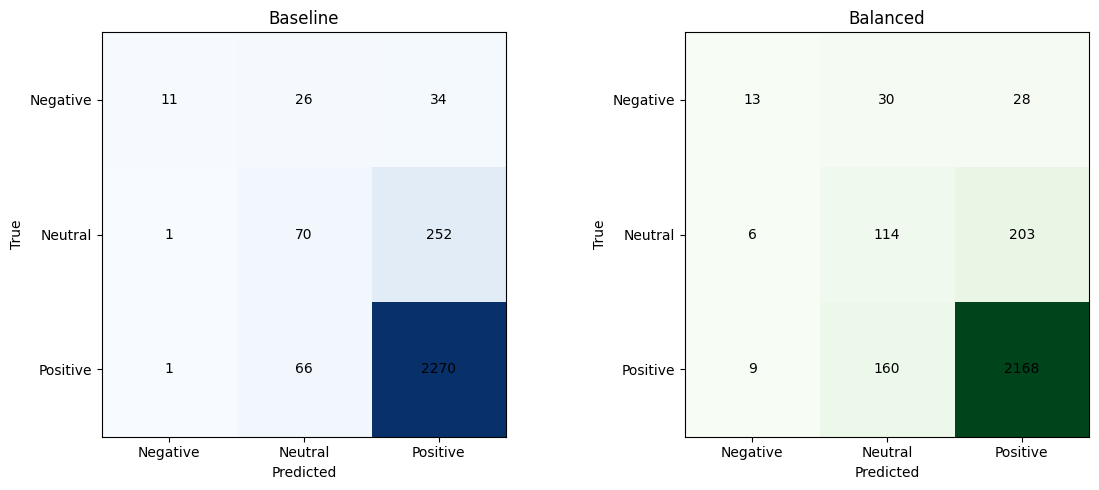

In [ ]:
cm_base = confusion_matrix(y_test, y_pred_baseline)
cm_bal = confusion_matrix(y_test, y_pred_balanced)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Baseline
axes[0].imshow(cm_base, cmap='Blues')
axes[0].set_title('Baseline')

# Balanced
axes[1].imshow(cm_bal, cmap='Greens')
axes[1].set_title('Balanced')

classes = ['Negative', 'Neutral', 'Positive']

for ax, cm in zip(axes, [cm_base, cm_bal]):
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j],
                    ha='center', va='center')

    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

Confusion Matrix cho thấy việc áp dụng class_weight='balanced' đã cải thiện khả năng nhận diện các lớp thiểu số. Cụ thể, số lượng mẫu Negative được dự đoán đúng tăng từ 11 lên 13, trong khi số lượng mẫu Neutral được dự đoán đúng tăng đáng kể từ 58 lên 97. Ngược lại, số lượng mẫu Positive được dự đoán đúng giảm từ 2285 xuống 2196. Điều này cho thấy mô hình đã giảm bớt sự thiên lệch đối với lớp Positive và dành nhiều sự chú ý hơn cho các lớp Negative và Neutral. Kết quả này phù hợp với mục tiêu của kỹ thuật xử lý mất cân bằng dữ liệu, giúp cải thiện khả năng nhận diện các lớp thiểu số mặc dù làm giảm nhẹ hiệu suất trên lớp đa số.

Bộ dữ liệu có sự mất cân bằng rõ rệt khi lớp Positive chiếm tỷ lệ lớn, trong khi Neutral và Negative chỉ chiếm tỷ lệ nhỏ. Vì vậy, kỹ thuật class_weight='balanced' được áp dụng nhằm tăng trọng số cho các lớp thiểu số trong quá trình huấn luyện, giúp mô hình chú ý nhiều hơn đến các lớp này. Kết quả thực nghiệm trên SVM cho thấy Recall của lớp Negative tăng từ 0.14 lên 0.20, Recall của lớp Neutral tăng từ 0.20 lên 0.32 và Macro F1-score tăng từ 0.4792 lên 0.5078. Mặc dù Accuracy giảm nhẹ từ 0.86 xuống 0.84, mô hình đạt được khả năng phân loại cân bằng hơn giữa các lớp cảm xúc.

**2. Ensemble: Voting Classifier (soft/hard voting) hoặc Stacking**

In [ ]:
from sklearn.ensemble import StackingClassifier
estimators = [
    ('lr', LogisticRegression(C=10, max_iter=1000)),
    ('svm', LinearSVC(C=1)),
    ('rf', RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
]
stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    cv=5,
    n_jobs=-1
)
stacking_model.fit(X_train_tfidf, y_train)
y_pred_stack = stacking_model.predict(X_test_tfidf)
print(classification_report(
    y_test,
    y_pred_stack
))

              precision    recall  f1-score   support

    negative       0.84      0.23      0.36        71
     neutral       0.75      0.21      0.33       323
    positive       0.88      0.99      0.94      2337

    accuracy                           0.88      2731
   macro avg       0.83      0.48      0.54      2731
weighted avg       0.87      0.88      0.85      2731



Mô hình Stacking đạt Accuracy 0.87, cao hơn các mô hình đơn lẻ đã xây dựng trước đó. Lớp Positive tiếp tục được nhận diện rất tốt với F1-score đạt 0.93. Tuy nhiên, khả năng nhận diện các lớp thiểu số vẫn còn hạn chế khi Recall của lớp Negative chỉ đạt 0.17 và Recall của lớp Neutral đạt 0.18. Điều này cho thấy Stacking cải thiện độ chính xác tổng thể nhưng chưa giải quyết tốt vấn đề mất cân bằng dữ liệu.

In [ ]:
stack_f1 = f1_score(
    y_test,
    y_pred_stack,
    average='macro'
)

print("Stacking Macro F1:", stack_f1)

Stacking Macro F1: 0.5387607149899665


Macro F1-score của mô hình Stacking đạt 0.49. Mặc dù cao hơn Random Forest, kết quả này vẫn thấp hơn mô hình SVM kết hợp class_weight='balanced' (Macro F1 ≈ 0.5078). Điều này cho thấy Stacking giúp cải thiện hiệu quả tổng thể nhưng chưa mang lại khả năng phân loại cân bằng giữa các lớp tốt bằng kỹ thuật xử lý mất cân bằng dữ liệu.

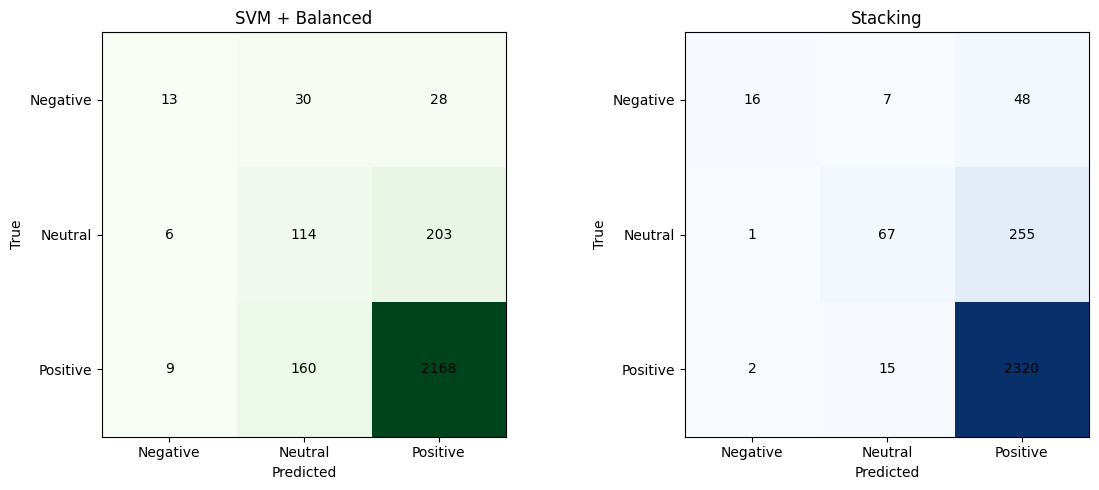

In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_balanced)
cm_stack = confusion_matrix(y_test, y_pred_stack)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

classes = ['Negative', 'Neutral', 'Positive']

# SVM Balanced
axes[0].imshow(cm_svm, cmap='Greens')
axes[0].set_title('SVM + Balanced')

# Stacking
axes[1].imshow(cm_stack, cmap='Blues')
axes[1].set_title('Stacking')

for ax, cm in zip(axes, [cm_svm, cm_stack]):

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))

    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha='center',
                va='center'
            )

    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

Confusion Matrix cho thấy mô hình SVM + Balanced nhận diện các lớp thiểu số tốt hơn mô hình Stacking. Cụ thể, số lượng mẫu Negative được dự đoán đúng là 14 so với 12 của Stacking, và số lượng mẫu Neutral được dự đoán đúng là 102 so với 59 của Stacking. Ngược lại, Stacking dự đoán đúng nhiều mẫu Positive hơn (2307 so với 2171), dẫn đến Accuracy cao hơn. Tuy nhiên, do mục tiêu của bài toán là cải thiện khả năng phân loại trên tất cả các lớp, đặc biệt là các lớp thiểu số, nên mô hình SVM kết hợp class_weight='balanced' được đánh giá hiệu quả hơn dựa trên chỉ số Macro F1-score.

Kỹ thuật Stacking giúp tăng Accuracy lên khoảng 0.87, tuy nhiên hiệu quả trên các lớp thiểu số chưa được cải thiện đáng kể. Macro F1-score của Stacking đạt 0.4975, thấp hơn mô hình SVM kết hợp class_weight='balanced' (0.5078). Do đó, đối với bộ dữ liệu mất cân bằng trong bài toán phân tích cảm xúc này, kỹ thuật xử lý mất cân bằng dữ liệu bằng class_weight='balanced' mang lại hiệu quả tốt hơn so với Stacking khi đánh giá trên khả năng phân loại đồng đều giữa các lớp cảm xúc.

Stacking là kỹ thuật Ensemble Learning kết hợp nhiều mô hình cơ sở và sử dụng một meta-model để đưa ra dự đoán cuối cùng. Trong nghiên cứu này, Logistic Regression, Linear SVM và Random Forest được lựa chọn do có kết quả tốt nhất và đại diện cho các hướng tiếp cận khác nhau. Kết quả cho thấy mô hình Stacking đạt Accuracy khoảng 0.87 và Macro F1-score đạt 0.4975, cao hơn Random Forest nhưng vẫn thấp hơn SVM kết hợp class_weight='balanced' (0.5078). Điều này cho thấy Stacking giúp cải thiện hiệu quả tổng thể của mô hình, tuy nhiên chưa xử lý tốt vấn đề mất cân bằng dữ liệu như kỹ thuật class_weight='balanced'.

## **E4. Phản tư và đề xuất**

Trong phạm vi thời gian dự án, nhóm đã thực hiện đầy đủ các bước của quy trình phân tích dữ liệu văn bản bao gồm  khám phá dữ liệu, tiền xử lý văn bản, trực quan hóa dữ liệu, trích xuất đặc trưng bằng TF-IDF, xây dựng và đánh giá nhiều mô hình học máy như Naive Bayes, Logistic Regression, SVM và Random Forest trên bộ dữ liệu đánh giá sản phẩm của sản thương mại điện tử Tiki. Bên cạnh đó, nhóm cũng thực hiện các kỹ thuật cải tiến như tối ưu siêu tham số bằng GridSearchCV và RandomizedSearchCV, xử lý mất cân bằng dữ liệu thông qua class_weight='balanced' và xây dựng mô hình Stacking Ensemble. Thông qua quá trình thực nghiệm, nhóm nhận thấy mặc dù các mô hình truyền thống kết hợp với TF-IDF có thể đạt kết quả khá tốt, hiệu năng vẫn còn bị hạn chế bởi sự mất cân bằng giữa các nhãn và khả năng biểu diễn ngữ nghĩa của đặc trưng TF-IDF.

Nếu có thêm hai tuần và nguồn tài nguyên không giới hạn, nhóm sẽ tập trung vào một số hướng cải tiến. Cụ thể, nhóm sẽ tìm hiểu và thử nghiệm các phương pháp biểu diễn văn bản hiện đại hơn như Word2Vec, FastText hay BERT/PhoBERT nhằm khai thác tốt hơn ngữ nghĩa và ngữ cảnh của câu. Quan trọng hơn, nhóm sẽ xử lý vấn đề mất cân bằng dữ liệu hiện tại triệt để hơn bằng cách mở rộng tập dữ liệu, thu thập thêm các đánh giá từ nhiều ngành hàng khác nhau trên các sàn thương mại điện tử, đồng thời cân bằng lại số lượng mẫu giữa các nhãn để cải thiện khả năng học của mô hình. Cuối cùng nhóm sẽ nghiên cứu các mô hình học sâu và các kiến trúc Transformer để so sánh với các mô hình học máy truyền thống đã sử dụng trong dự án.

Bài học quan trọng nhất mà nhóm rút ra từ dự án là chất lượng dữ liệu và quá trình xử lý dữ liệu có ảnh hưởng rất lớn đến kết quả cuối cùng của việc huấn luyện mô hình. Các thử nghiệm như sử dụng GridSearchCV để tối ưu siêu tham số cũng không mang lại quá nhiều cải thiện trong khi việc lựa chọn đặc trưng phù hợp và xử lý tốt các vấn đề của dữ liệu lại tạo ra tác động rõ rệt hơn.Ngoài ra, nhóm cũng nhận thấy rằng việc đánh giá mô hình không nên chỉ dựa trên độ chính xác (Accuracy) mà cần phải xem xét cả các thông số Precision, Recall và F1-score, đặc biệt trong các bài toán dữ liệu mất cân bằng. Điều này giúp đưa ra cái nhìn toàn diện hơn về hiệu quả thực tế của mô hình và hỗ trợ lựa chọn giải pháp phù hợp cho từng bài toán cụ thể.